# Human-in-the-Loop Active Learning for Waste Classification

PracticalLab 1 — Trustworthy and Responsible Artificial Intelligence (TRAI).

## 1. Introduction and Objectives

Este notebook contém **todo o código Python do projeto** (não há módulos `.py` locais). Objetivos:

- auditar o dataset Kaggle *Garbage Classification* (12 classes, versão 1) e documentar a curadoria humana
  (exclusão de três duplicados exatos mal rotulados);
- fixar um protocolo experimental comum (splits, pool inicial de 200 imagens, Macro-F1 como métrica principal e AULC como complementar);
- **Active Learning** com features MobileNetV2 (extrator pré-treinado) + Logistic Regression: quatro estratégias
  (Random, Least Confidence, Margin, Entropy), cinco seeds, orçamento até 5 000 imagens, Full Training Baseline;
- interfaces **Human-in-the-Loop** (anotação interativa e revisão de duplicados).

**Execução:** o notebook pode ser executado sequencialmente (*Restart & Run All*). As etapas demoradas
ou que escrevem artefactos estão protegidas por flags na secção 2, todas `False` por omissão:

| Flag | Efeito quando `True` |
| --- | --- |
| `REGENERATE_FEATURES` | Volta a extrair as features MobileNetV2 (só é automático se `garbage_features.npz` não existir). |
| `REFRESH_MANIFESTS` | Reaplica `excluded_images.csv` aos manifestos (idempotente; nunca refaz splits). |
| `RUN_EXPERIMENT_A` | Executa o protocolo completo de Active Learning (~15 min, retomável). |

## 2. Environment and Imports

In [42]:
import csv
import hashlib
import json
import os
import platform
import time
from collections import Counter, defaultdict
from datetime import datetime, timezone
from html import escape
from io import BytesIO
from pathlib import Path, PurePosixPath
from uuid import uuid4

import ipywidgets as widgets
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from IPython.display import Markdown, clear_output, display
from PIL import Image, ImageOps
from scipy.fft import dctn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

In [ ]:
# Flags de execução (ver secção 1)
REGENERATE_FEATURES = False
REFRESH_MANIFESTS = False
RUN_EXPERIMENT_A = True

## 3. Dataset Loading

Constantes do protocolo, leitura dos manifestos versionados em `data/manifests/`, download via KaggleHub
(cache nativa, fora do repositório) e a classe `GarbageDataset`. A versão `/versions/1` é fixa para evitar
alterações silenciosas do dataset. As imagens excluídas nunca entram em treino, validação, teste ou pools.

In [44]:
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
NOTEBOOK_PATH = PROJECT_ROOT / 'notebooks' / '01_waste_classification_hitl.ipynb'
MANIFEST_DIR = PROJECT_ROOT / 'data' / 'manifests'
REVIEW_DIR = PROJECT_ROOT / 'data' / 'review'
EDA_DIR = PROJECT_ROOT / 'artifacts' / 'eda'
FEATURES_FILE = PROJECT_ROOT / 'notebooks' / 'garbage_features.npz'
RESULTS_ROOT = PROJECT_ROOT / 'artifacts' / 'active_learning'

# Versao fixa para manter os dados das experiencias reproduziveis.
DATASET_HANDLE = 'mostafaabla/garbage-classification/versions/1'
SEED = 42
EXPECTED_COUNTS = {
    'battery': 945, 'biological': 985, 'brown-glass': 607, 'cardboard': 891,
    'clothes': 5325, 'green-glass': 629, 'metal': 769, 'paper': 1050,
    'plastic': 865, 'shoes': 1977, 'trash': 697, 'white-glass': 775,
}
EXPECTED_CLASSES = set(EXPECTED_COUNTS)
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
PHASH_DISTANCE = 4
EXCLUSIONS_FILE = MANIFEST_DIR / 'excluded_images.csv'
EXCLUSION_COLUMNS = ['relative_path', 'original_label', 'reason', 'kept_relative_path', 'provenance']
PARTITIONS = ('train', 'validation', 'test', 'labeled_initial', 'unlabeled')

In [45]:
def dataset_root():
    return Path(kagglehub.dataset_download(DATASET_HANDLE)) / 'garbage_classification'


def resolve_image(root, relative_path):
    """Os manifestos usam POSIX; rejeitar caminhos absolutos ou que saiam da raiz."""
    relative = PurePosixPath(relative_path)
    if relative.is_absolute() or '..' in relative.parts or '\\' in relative_path or ':' in relative_path:
        raise ValueError(f'Caminho relativo inválido: {relative_path}')
    path = Path(root).joinpath(*relative.parts)
    if not path.resolve().is_relative_to(Path(root).resolve()):
        raise ValueError(f'Caminho fora do dataset: {relative_path}')
    return path


def write_csv(path, rows, columns):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('w', encoding='utf-8', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=columns, lineterminator='\n')
        writer.writeheader()
        writer.writerows(rows)


def read_csv(path):
    with Path(path).open(encoding='utf-8', newline='') as stream:
        return list(csv.DictReader(stream))


def load_exclusions(path=EXCLUSIONS_FILE):
    """Imagens excluídas do dataset efetivo; os ficheiros Kaggle nunca são alterados."""
    exclusions = {}
    for row in read_csv(path):
        relative = PurePosixPath(row['relative_path'])
        kept = PurePosixPath(row['kept_relative_path'])
        if (list(row) != EXCLUSION_COLUMNS or len(relative.parts) != 2 or len(kept.parts) != 2
                or relative.parts[0] != row['original_label'] or row['original_label'] not in EXPECTED_COUNTS
                or any(c in row['relative_path'] + row['kept_relative_path'] for c in '\\:')
                or '..' in relative.parts + kept.parts
                or not row['reason'].strip() or not row['provenance'].strip()):
            raise ValueError(f'Exclusão inválida: {row}')
        if row['relative_path'] in exclusions:
            raise ValueError(f'Exclusão repetida: {relative}')
        exclusions[row['relative_path']] = row
    return exclusions


def excluded_paths(path=EXCLUSIONS_FILE):
    return frozenset(load_exclusions(path))


def excluded_images_revision(path=EXCLUSIONS_FILE):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def load_original_inventory(directory=MANIFEST_DIR):
    """Dataset Kaggle completo (15515), só para EDA/documentação; nunca para experiências."""
    return read_csv(Path(directory) / 'inventory.csv')


def load_effective_inventory(directory=MANIFEST_DIR):
    directory = Path(directory)
    exclusions = load_exclusions(directory / 'excluded_images.csv')
    records = load_original_inventory(directory)
    by_path = {record['relative_path']: record for record in records}
    for relative, row in exclusions.items():
        kept = by_path.get(row['kept_relative_path'])
        if (relative not in by_path or by_path[relative]['label'] != row['original_label'] or kept is None
                or kept['relative_path'] in exclusions or kept['sha256'] != by_path[relative]['sha256']):
            raise ValueError(f'Exclusão inconsistente com o inventário: {relative}')
    return [record for record in records if record['relative_path'] not in exclusions]


def read_partitions(directory=MANIFEST_DIR):
    return {name: [row['image_id'] for row in read_csv(Path(directory) / f'{name}.csv')] for name in PARTITIONS}

In [46]:
path = Path(kagglehub.dataset_download(DATASET_HANDLE))
print("Path to dataset files:", path)
DATASET_PATH = path / "garbage_classification"
if not DATASET_PATH.is_dir():
    raise FileNotFoundError(f"Diretorio das classes nao encontrado: {DATASET_PATH}")
if {p.name for p in DATASET_PATH.iterdir() if p.is_dir()} != EXPECTED_CLASSES:
    raise ValueError(f"Classes inesperadas em {DATASET_PATH}")

def fix_path(image_path):
    # Reutilizar features com caminhos de outra maquina, sempre na versao fixa.
    parts = str(image_path).replace("\\", "/").split("/")
    resolved_path = DATASET_PATH.joinpath(*parts[-2:])
    if not resolved_path.is_file():
        raise FileNotFoundError(f"Imagem nao encontrada: {resolved_path}")
    return str(resolved_path)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Definir device (GPU se disponível, senão CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"A usar o dispositivo: {device}")

Path to dataset files: C:\Users\35191\.cache\kagglehub\datasets\mostafaabla\garbage-classification\versions\1
A usar o dispositivo: cuda


In [47]:
# Dataset customizado em PyTorch para percorrer a estrutura de pastas
class GarbageDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []
        excluded = excluded_paths()  # exclusoes versionadas: nunca entram em treino/avaliacao
        
        # Guardar os nomes das pastas como classes
        self.class_names = sorted([d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))])
        self.class_to_idx = {class_name: i for i, class_name in enumerate(self.class_names)}
        
        for class_name in self.class_names:
            class_dir = os.path.join(root_dir, class_name)
            for img_name in os.listdir(class_dir):
                if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp')):
                    if (Path(class_dir) / img_name).relative_to(root_dir).as_posix() in excluded:
                        continue
                    self.image_paths.append(os.path.join(class_dir, img_name))
                    self.labels.append(self.class_to_idx[class_name])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
            
        return image, label, img_path

## 4. Exploratory Data Analysis (EDA)

Esta secção consulta a auditoria e os manifestos existentes e apresenta gráficos, sem repetir hashing ou divisões.

Fonte: [Kaggle — Garbage Classification (12 classes)](https://www.kaggle.com/datasets/mostafaabla/garbage-classification/versions/1),
`mostafaabla/garbage-classification/versions/1`. A raiz contém as pastas das classes.
Nenhuma imagem é copiada, removida ou alterada. As análises globais seguintes são uma auditoria de
qualidade e desenho do protocolo anterior ao treino; não serão utilizadas para escolher modelos a partir do teste.

### 4.1 Funções da auditoria

`scan_dataset` (SHA-256, verificação/descodificação Pillow e pHash DCT de 64 bits, com cache em `artifacts/eda/`),
`exact_groups` e `visual_candidates` geraram `inventory.csv` e `visual_candidates.csv`. A auditoria **não é
reexecutada** pelo notebook; as funções ficam disponíveis para reprodutibilidade e para as validações.

In [48]:
def scan_dataset(root, cache_path=PROJECT_ROOT / 'artifacts' / 'eda' / 'image_cache.json'):
    """Reutiliza hashes/decodificação se o caminho, tamanho e mtime_ns não mudaram."""
    root = Path(root)
    classes = sorted(p.name for p in root.iterdir() if p.is_dir())
    if set(classes) != set(EXPECTED_COUNTS):
        raise ValueError(f'Classes inesperadas: {classes}')
    cache_path = Path(cache_path)
    cache = json.loads(cache_path.read_text(encoding='utf-8')) if cache_path.exists() else {}
    if cache.get('schema') != 'sha256-phash-dct64-v1' or cache.get('dataset') != DATASET_HANDLE:
        cache = {}
    previous = cache.get('files', {})
    updated, records = {}, []
    files = sorted((p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES),
                   key=lambda p: p.relative_to(root).as_posix())
    for index, path in enumerate(files):
        relative = path.relative_to(root).as_posix()
        if len(PurePosixPath(relative).parts) != 2:
            raise ValueError(f'Estrutura inesperada: {relative}')
        stat = path.stat()
        signature = [stat.st_size, stat.st_mtime_ns]
        old = previous.get(relative)
        if old and old['signature'] == signature:
            record = old['record']
        else:
            with path.open('rb') as stream:
                sha256 = hashlib.file_digest(stream, 'sha256').hexdigest()
            record = dict(image_id=hashlib.sha256(relative.encode()).hexdigest(), relative_path=relative,
                          label=path.parent.name, bytes=stat.st_size, sha256=sha256,
                          width='', height='', aspect_ratio='', format='', mode='', phash='', error='')
            try:
                with Image.open(path) as image:
                    image.verify()
                with Image.open(path) as image:
                    image.load()
                    record.update(width=image.width, height=image.height,
                                  aspect_ratio=image.width / image.height, format=image.format, mode=image.mode)
                    gray = ImageOps.exif_transpose(image).convert('L').resize((32, 32), Image.Resampling.LANCZOS)
                    coefficients = dctn(np.asarray(gray, dtype=float), type=2, norm='ortho')[:8, :8].ravel()
                    bits = coefficients > np.median(coefficients[1:])
                    record['phash'] = f'{sum(int(bit) << i for i, bit in enumerate(bits)):016x}'
            except (OSError, ValueError, Image.DecompressionBombError) as error:
                record['error'] = f'{type(error).__name__}: {error}'
        updated[relative] = dict(signature=signature, record=record)
        records.append(record)
        if (index + 1) % 1000 == 0:
            print(f'EDA: {index + 1}/{len(files)} imagens', flush=True)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    cache_path.write_text(json.dumps(dict(schema='sha256-phash-dct64-v1', dataset=DATASET_HANDLE,
                                         files=updated), ensure_ascii=False), encoding='utf-8')
    return records


def exact_groups(records):
    groups = defaultdict(list)
    for record in records:
        groups[record['sha256']].append(record)
    return [group for _, group in sorted(groups.items()) if len(group) > 1]


def visual_candidates(records):
    """pHash 64 bits, distância <=4; cinco blocos evitam testar todos os pares."""
    buckets, pairs = defaultdict(list), []
    for index, record in enumerate(records):
        if not record['phash']:
            continue
        value = int(record['phash'], 16)
        keys, offset = [], 0
        for block, width in enumerate((13, 13, 13, 13, 12)):
            keys.append((block, (value >> offset) & ((1 << width) - 1)))
            offset += width
        candidates = {other for key in keys for other in buckets[key]}
        for other in sorted(candidates):
            previous = records[other]
            if previous['sha256'] == record['sha256']:
                continue
            distance = (value ^ int(previous['phash'], 16)).bit_count()
            if distance <= PHASH_DISTANCE:
                pairs.append(dict(image_id_a=previous['image_id'], image_id_b=record['image_id'],
                                  distance=distance, cross_class=previous['label'] != record['label']))
        for key in keys:
            buckets[key].append(index)
    return pairs

### 4.2 Inventário original

In [49]:
EDA_DIR.mkdir(parents=True, exist_ok=True)

# A EDA usa o inventario Kaggle original (15515), anterior as exclusoes.
eda_records = load_original_inventory()
eda_effective_records = load_effective_inventory()
eda_df = pd.DataFrame(eda_records)
eda_counts = eda_df.groupby("label").size().rename("imagens").to_frame()
eda_counts["percentagem"] = 100 * eda_counts["imagens"] / len(eda_df)
display(Markdown(f"**Distribuição original Kaggle — dataset:** Garbage Classification; **versão:** 1; **origem:** Kaggle; "
                 f"**imagens:** {len(eda_df):,}; **classes:** {len(eda_counts)}."))
display(eda_counts.round(3))

**Distribuição original Kaggle — dataset:** Garbage Classification; **versão:** 1; **origem:** Kaggle; **imagens:** 15,515; **classes:** 12.

,imagens,percentagem
label,,
battery,945,6.091
biological,985,6.349
brown-glass,607,3.912
cardboard,891,5.743
clothes,5325,34.322
green-glass,629,4.054
metal,769,4.956
paper,1050,6.768
plastic,865,5.575


### 4.3 Distribuição das classes e desequilíbrio

As contagens incluem todos os ficheiros, incluindo cópias exatas. As percentagens usam como denominador
o total do dataset. A razão maior/minor quantifica o desequilíbrio; não se aplica balanceamento.
A futura comparação usará **Macro-F1**, dando igual peso às 12 classes, em conjunto com métricas por classe.

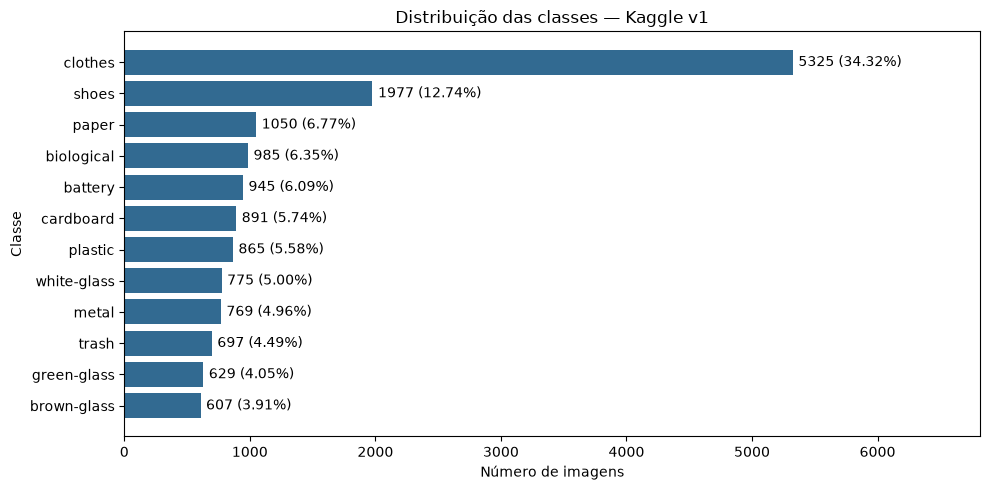

A classe maioritária é **clothes** (34.32%) e a minoritária é **brown-glass** (3.91%). A razão é **8.77:1**. Uma accuracy global elevada pode ocultar resultados fracos nas classes menos representadas; a distribuição do pool inicial será estratificada, sem alterar a frequência dos dados por balanceamento.

In [50]:
eda_ordered = eda_counts.sort_values("imagens")
fig, ax = plt.subplots(figsize=(10, 5))
eda_bars = ax.barh(eda_ordered.index, eda_ordered["imagens"], color="#326a91")
ax.bar_label(eda_bars, labels=[f"{n} ({pct:.2f}%)" for n, pct in eda_ordered.itertuples(index=False)], padding=4)
ax.set(xlabel="Número de imagens", ylabel="Classe", title="Distribuição das classes — Kaggle v1")
ax.set_xlim(0, eda_counts["imagens"].max() * 1.28)
fig.tight_layout()
fig.savefig(EDA_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
eda_major = eda_counts["imagens"].idxmax()
eda_minor = eda_counts["imagens"].idxmin()
display(Markdown(
    f"A classe maioritária é **{eda_major}** ({eda_counts.loc[eda_major, 'percentagem']:.2f}%) e a "
    f"minoritária é **{eda_minor}** ({eda_counts.loc[eda_minor, 'percentagem']:.2f}%). "
    f"A razão é **{eda_counts.loc[eda_major, 'imagens'] / eda_counts.loc[eda_minor, 'imagens']:.2f}:1**. "
    "Uma accuracy global elevada pode ocultar resultados fracos nas classes menos representadas; "
    "a distribuição do pool inicial será estratificada, sem alterar a frequência dos dados por balanceamento."
))

### 4.4 Dimensões, resoluções, aspect ratios, formatos e integridade

Na auditoria original, cada imagem passou por `Pillow.verify()` e descodificação completa (`load()`). Reutilizam-se largura,
altura, razão largura/altura, formato real e modo de cor. Erros são apresentados e impedem a geração
de splits, em vez de excluir silenciosamente ficheiros. A cache em `artifacts/eda/` reutiliza o resultado
quando caminho relativo, tamanho e `mtime_ns` não mudam; apagar essa cache força uma nova auditoria completa.

**Imagens ilegíveis/corrompidas detetadas:** 0.

,relative_path,error


,width,height,aspect_ratio
count,15515.000,15515.000,15515.000
mean,349.822,351.706,1.084
std,117.549,149.418,0.352
min,51.000,100.000,0.128
5%,194.000,177.000,0.665
25%,234.000,224.000,0.750
50%,400.000,384.000,1.000
75%,400.000,533.000,1.333
95%,512.000,534.000,1.651
max,888.000,936.000,5.020


**Resoluções distintas:** 892; abaixo, as 15 mais frequentes.

,,imagens
width,height,
400,533,2590
512,384,2358
225,225,2004
400,534,1077
275,183,691
259,194,550
533,400,388
400,711,300
194,259,230


imagens
extension format mode         
.jpg      JPEG   RGB     15481
          PNG    P          34

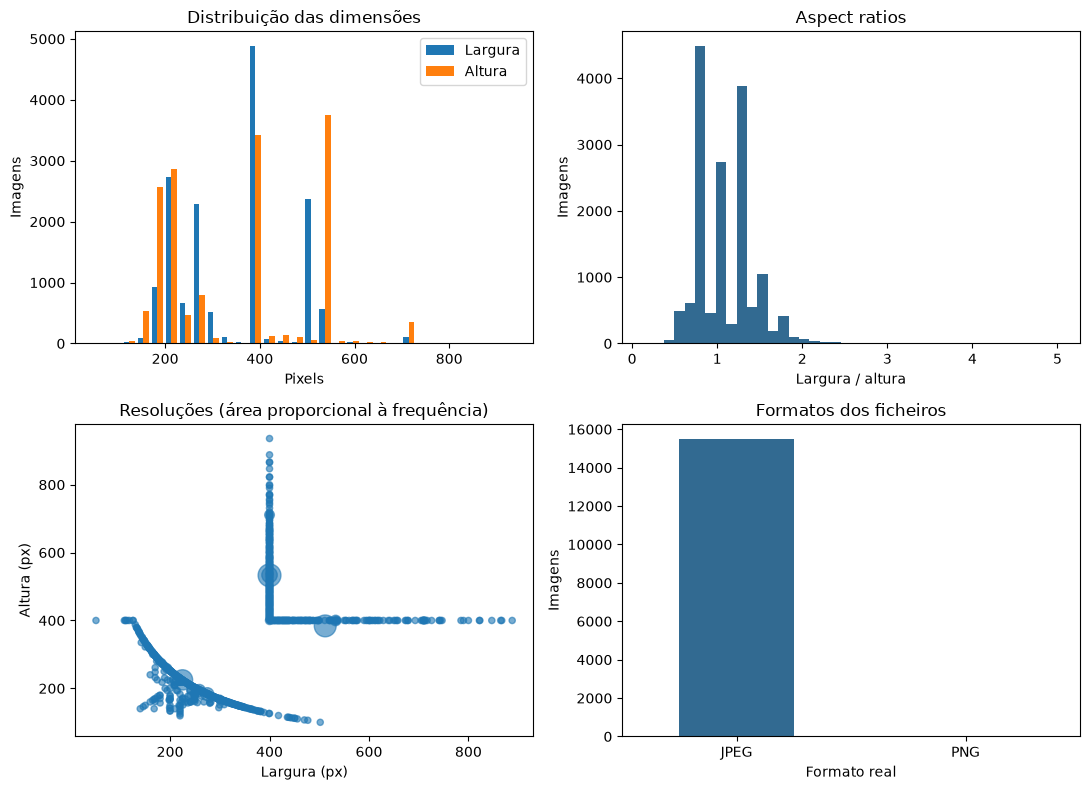

In [51]:
eda_errors = eda_df.loc[eda_df["error"] != "", ["relative_path", "error"]]
display(Markdown(f"**Imagens ilegíveis/corrompidas detetadas:** {len(eda_errors)}."))
display(eda_errors)
eda_valid = eda_df.loc[eda_df["error"] == ""].copy()
eda_valid[["width", "height", "aspect_ratio"]] = eda_valid[["width", "height", "aspect_ratio"]].apply(pd.to_numeric)
display(eda_valid[["width", "height", "aspect_ratio"]].describe(percentiles=[.05, .25, .5, .75, .95]).round(3))
eda_resolutions = eda_valid.groupby(["width", "height"]).size().rename("imagens").sort_values(ascending=False)
display(Markdown(f"**Resoluções distintas:** {len(eda_resolutions)}; abaixo, as 15 mais frequentes."))
display(eda_resolutions.head(15).to_frame())
eda_valid["extension"] = eda_valid["relative_path"].map(lambda p: Path(p).suffix.lower())
display(eda_valid.groupby(["extension", "format", "mode"]).size().rename("imagens").to_frame())

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist([eda_valid["width"], eda_valid["height"]], bins=30, label=["Largura", "Altura"])
axes[0, 0].set(xlabel="Pixels", ylabel="Imagens", title="Distribuição das dimensões")
axes[0, 0].legend()
axes[0, 1].hist(eda_valid["aspect_ratio"], bins=40, color="#326a91")
axes[0, 1].set(xlabel="Largura / altura", ylabel="Imagens", title="Aspect ratios")
eda_resolution_frame = eda_resolutions.reset_index()
axes[1, 0].scatter(eda_resolution_frame["width"], eda_resolution_frame["height"],
                   s=20 + 250 * eda_resolution_frame["imagens"] / eda_resolution_frame["imagens"].max(), alpha=.6)
axes[1, 0].set(xlabel="Largura (px)", ylabel="Altura (px)", title="Resoluções (área proporcional à frequência)")
eda_valid.groupby("format").size().plot.bar(ax=axes[1, 1], color="#326a91", rot=0)
axes[1, 1].set(xlabel="Formato real", ylabel="Imagens", title="Formatos dos ficheiros")
fig.tight_layout()
fig.savefig(EDA_DIR / "image_dimensions.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5 Exemplos de todas as classes

Seleciona-se uma imagem por classe a partir de caminhos ordenados, com um gerador local e seed 42.
As miniaturas são apenas para inspeção e não alteram os ficheiros originais. Os outputs destas imagens
não ficam guardados no notebook versionado; executar a célula para os visualizar localmente.

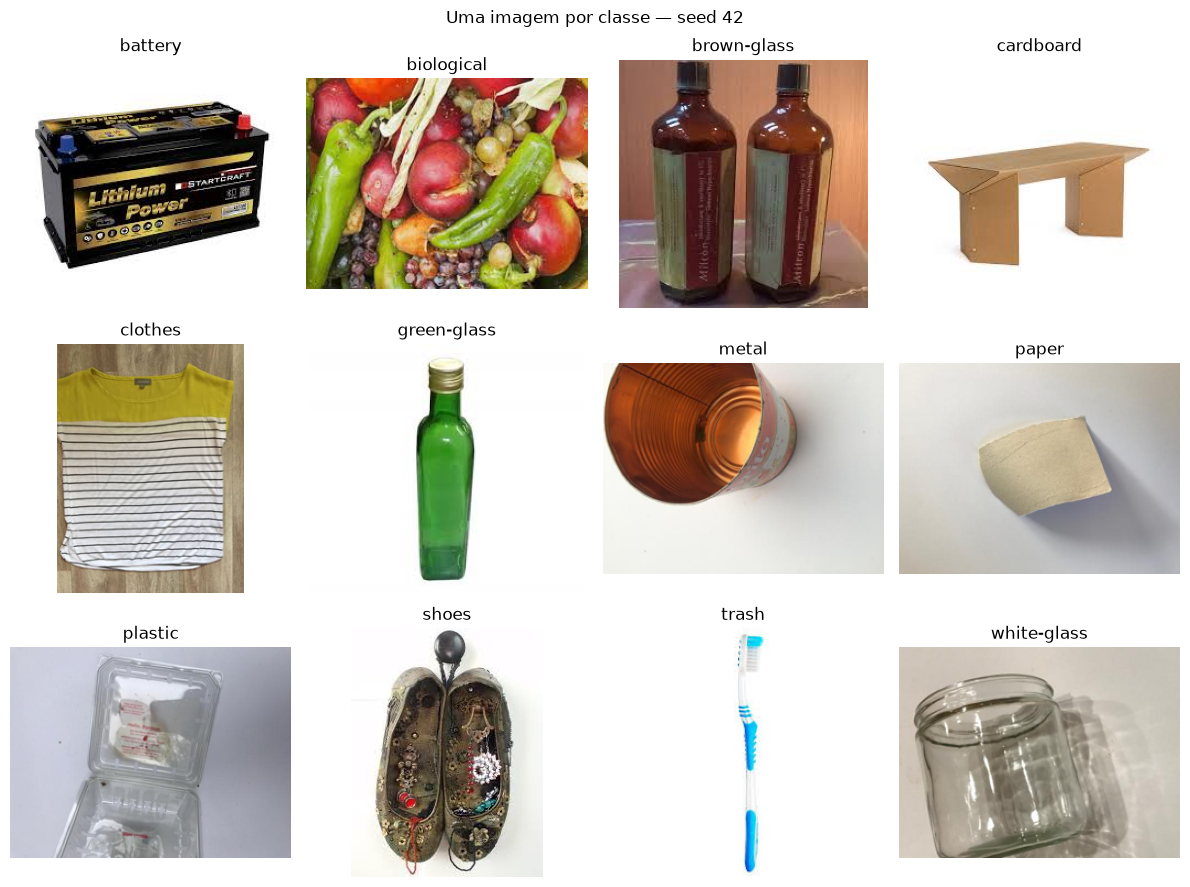

In [52]:
eda_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
eda_sample_ids = []
for eda_ax, eda_label in zip(axes.flat, eda_counts.index):
    eda_options = eda_valid.loc[eda_valid["label"] == eda_label].sort_values("relative_path")
    eda_sample = eda_options.iloc[int(eda_rng.integers(len(eda_options)))]
    eda_sample_ids.append(eda_sample["image_id"])
    with Image.open(resolve_image(DATASET_PATH, eda_sample["relative_path"])) as eda_image:
        eda_preview = eda_image.convert("RGB")
        eda_preview.thumbnail((256, 256))
        eda_ax.imshow(eda_preview)
    eda_ax.set_title(eda_label)
    eda_ax.axis("off")
fig.suptitle("Uma imagem por classe — seed 42")
fig.tight_layout()
fig.savefig(EDA_DIR / "class_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Duplicate Analysis and Dataset Cleaning

### 5.1 Duplicados confirmados e candidatos visuais

**Confirmados:** SHA-256 dos bytes do ficheiro; distingue-se número de grupos, imagens envolvidas e
cópias redundantes (`Σ(tamanho do grupo − 1)`). Grupos com classes diferentes seriam conflitos de rótulo.

**Candidatos:** pHash de 64 bits, DCT-II sobre grayscale 32×32 após orientação EXIF, bloco 8×8 e limiar
pela mediana sem DC. Distância de Hamming ≤4. Um índice de cinco blocos cobre todos os pares dentro
desse limiar sem comparar exaustivamente todos os pares. Pares SHA-256 idênticos não são recontados.
Esta heurística pode produzir falsos positivos e negativos: sem revisão humana, não confirma duplicação
semântica, nem deteta necessariamente recortes, rotações ou fotografias diferentes do mesmo objeto.

In [53]:
eda_exact = exact_groups(eda_records)
eda_candidates = [dict(pair, distance=int(pair["distance"]), cross_class=pair["cross_class"] == "True")
                  for pair in read_csv(MANIFEST_DIR / "visual_candidates.csv")]
eda_lookup = {r["image_id"]: r for r in eda_records}
eda_exact_rows = [{"sha256": group[0]["sha256"], "imagens": len(group),
                   "classes": ", ".join(sorted({r["label"] for r in group})),
                   "caminhos": "; ".join(r["relative_path"] for r in group)} for group in eda_exact]
display(Markdown(
    f"**Exatos:** {len(eda_exact)} grupos, {sum(map(len, eda_exact))} imagens envolvidas, "
    f"{sum(len(g) - 1 for g in eda_exact)} cópias redundantes; "
    f"{sum(len({r['label'] for r in g}) > 1 for g in eda_exact)} grupos entre classes. "
    f"**Visuais:** {len(eda_candidates)} pares candidatos (excluindo os exatos), "
    f"{len({p[k] for p in eda_candidates for k in ('image_id_a', 'image_id_b')})} imagens envolvidas, "
    f"{sum(p['cross_class'] for p in eda_candidates)} pares entre classes."
))
display(pd.DataFrame(eda_exact_rows))
eda_candidate_table = pd.DataFrame([
    {"imagem_a": eda_lookup[p["image_id_a"]]["relative_path"],
     "imagem_b": eda_lookup[p["image_id_b"]]["relative_path"],
     "distancia": p["distance"], "classes_diferentes": p["cross_class"]} for p in eda_candidates])
display(eda_candidate_table.head(20))

**Exatos:** 18 grupos, 37 imagens envolvidas, 19 cópias redundantes; 3 grupos entre classes. **Visuais:** 234 pares candidatos (excluindo os exatos), 331 imagens envolvidas, 55 pares entre classes.

,sha256,imagens,classes,caminhos
0,0d6aa0fb5d7b506d9e032c548a0a5038744754746fb3cf...,2,green-glass,green-glass/green-glass285.jpg; green-glass/gr...
1,17e65561542286d6b6d915bd65054a972bfee7a7b8e76e...,2,green-glass,green-glass/green-glass403.jpg; green-glass/gr...
2,28df9278c6345536ecdd34f88c48768c0ba04843e3a1aa...,2,green-glass,green-glass/green-glass476.jpg; green-glass/gr...
3,2fac090c28407dcf657fab4a3443fde433060ba699b75e...,2,green-glass,green-glass/green-glass336.jpg; green-glass/gr...
4,3b83999c47c07b0f4647a552b6ac82c344670afbcf6955...,2,green-glass,green-glass/green-glass449.jpg; green-glass/gr...
5,3ba6968afff8fc059b69a0dbb03ae11fc7cf43a4fa604d...,2,clothes,clothes/clothes2051.jpg; clothes/clothes5234.jpg
6,3fc22a23ecac1de0fc12c487650571327f7adb3aaffb6f...,2,green-glass,green-glass/green-glass388.jpg; green-glass/gr...
7,42d4f169ff5d7f045f45a561bb61de342ad80218236f7a...,2,green-glass,green-glass/green-glass424.jpg; green-glass/gr...
8,4866996c89523ccabe83e966063d08b27d1b82698ab225...,2,green-glass,green-glass/green-glass471.jpg; green-glass/gr...
9,6459b86829072594aea6d5f89946a5deb2b8302cf810df...,2,green-glass,green-glass/green-glass231.jpg; green-glass/gr...


,imagem_a,imagem_b,distancia,classes_diferentes
0,battery/battery104.jpg,battery/battery168.jpg,4,False
1,battery/battery270.jpg,battery/battery327.jpg,4,False
2,battery/battery268.jpg,battery/battery343.jpg,0,False
3,battery/battery129.jpg,battery/battery35.jpg,0,False
4,battery/battery268.jpg,battery/battery357.jpg,4,False
5,battery/battery343.jpg,battery/battery357.jpg,4,False
6,battery/battery340.jpg,battery/battery461.jpg,2,False
7,battery/battery293.jpg,battery/battery467.jpg,2,False
8,battery/battery128.jpg,battery/battery777.jpg,2,False
9,battery/battery63.jpg,battery/battery833.jpg,0,False


### 5.2 Human-reviewed exact duplicates with conflicting original labels

Foram identificados **três grupos de duplicados exatos (SHA-256) com rótulos contraditórios** entre classes.
Os três casos foram revistos visualmente por um anotador humano, que decidiu **excluir as três cópias
incorretamente rotuladas** e **preservar as cópias corretamente rotuladas**. Os rótulos Kaggle não foram
alterados e o dataset original não foi modificado: os ficheiros continuam na cache Kaggle e a exclusão é
definida apenas por `data/manifests/excluded_images.csv`. Nenhuma imagem excluída entra em treino,
validação, teste ou nos pools de Active Learning; ficam acessíveis só para esta demonstração do EDA.
A demonstração usa os dados originais (pré-exclusão) e mostra, por imagem, o ficheiro, a classe original
Kaggle, o grupo (identificador) e se foi **excluída** ou **mantida**.

In [54]:
def preview_image(root, member):
    """Validar só os ficheiros abertos, sem repetir hashing de todo o dataset."""
    content = resolve_image(root, member['relative_path']).read_bytes()
    if hashlib.sha256(content).hexdigest() != member['sha256']:
        raise ValueError(f'Imagem diferente da EDA: {member["relative_path"]}')
    with Image.open(BytesIO(content)) as image:
        preview = ImageOps.exif_transpose(image).convert('RGB')
        preview.thumbnail((640, 640))
        output = BytesIO()
        preview.save(output, format='PNG')
        return output.getvalue()


def load_reviewed_exact_cases():
    """Usa o inventário Kaggle original (pré-exclusão), só para análise e documentação."""
    records = load_original_inventory()
    exclusions = load_exclusions()
    splits = {key: name for name, ids in read_partitions().items()
              if name in ('train', 'validation', 'test') for key in ids}
    cases = []
    for group in exact_groups(records):
        if len({record['label'] for record in group}) < 2:
            continue
        ids = sorted(record['image_id'] for record in group)
        key = json.dumps([DATASET_HANDLE, 'exact', ids], separators=(',', ':'))
        cases.append(dict(case_id=f'exact-{hashlib.sha256(key.encode()).hexdigest()}', images=[
            dict(image_id=record['image_id'], relative_path=record['relative_path'], original_label=record['label'],
                 status='excluded' if record['relative_path'] in exclusions else 'kept',
                 sha256=record['sha256'], split=splits.get(record['image_id'], 'excluída'))
            for record in sorted(group, key=lambda row: row['relative_path'])]))
    return {'exact': sorted(cases, key=lambda case: case['case_id'])}


def case_panel(case, root):
    heading = widgets.HTML(
        f'<div style="overflow-wrap:anywhere"><b>Identificador:</b> <code>{escape(case["case_id"])}</code>'
        '<br><b>Tipo:</b> duplicado exato SHA-256 com rótulos contraditórios, revisto por anotador humano</div>')
    cards = []
    for member in case['images']:
        cards.append(widgets.VBox([
            widgets.HTML(f'<b style="font-size:18px;color:{"#c0392b" if member["status"] == "excluded" else "#1e8449"}">'
                         f'{"EXCLUÍDA" if member["status"] == "excluded" else "MANTIDA"}</b><br>'
                         f'<b style="font-size:18px">Classe original Kaggle: {escape(member["original_label"])}</b><br>'
                         f'<b>Ficheiro:</b> {escape(Path(member["relative_path"]).name)}<br>'
                         f'<code>{escape(member["relative_path"])}</code><br>Split: {escape(member["split"])}'),
            widgets.Image(value=preview_image(root, member), format='png', width=440),
        ], layout=widgets.Layout(min_width='460px', width='460px')))
    images = widgets.HBox(cards, layout=widgets.Layout(flex_flow='row nowrap', overflow='auto', width='100%'))
    return widgets.VBox([heading, images])


def exact_conflicts_view(cases, root=None):
    root = dataset_root() if root is None else Path(root)
    return widgets.VBox([case_panel(case, root) for case in cases['exact']])

In [55]:
eda_exclusions = pd.DataFrame(read_csv(MANIFEST_DIR / "excluded_images.csv"))
display(eda_exclusions[["relative_path", "original_label", "kept_relative_path", "reason", "provenance"]])
eda_reviewed_cases = load_reviewed_exact_cases()
eda_exact_conflicts_ui = exact_conflicts_view(eda_reviewed_cases)
display(eda_exact_conflicts_ui)

,relative_path,original_label,kept_relative_path,reason,provenance
0,plastic/plastic159.jpg,plastic,white-glass/white-glass129.jpg,duplicado exato (SHA-256) com rótulo incorreto...,revisão visual humana
1,metal/metal459.jpg,metal,white-glass/white-glass412.jpg,duplicado exato (SHA-256) com rótulo incorreto...,revisão visual humana
2,white-glass/white-glass761.jpg,white-glass,plastic/plastic556.jpg,duplicado exato (SHA-256) com rótulo incorreto...,revisão visual humana


### 5.3 Distribuição original vs. dataset efetivo

In [56]:
eda_original_df = pd.DataFrame(load_original_inventory())
eda_effective_df = pd.DataFrame(load_effective_inventory())
eda_label_comparison = pd.concat([
    eda_original_df["label"].value_counts().rename("Kaggle original"),
    eda_effective_df["label"].value_counts().rename("Dataset efetivo"),
], axis=1).sort_index()
eda_label_comparison["excluidas"] = eda_label_comparison["Kaggle original"] - eda_label_comparison["Dataset efetivo"]
display(eda_label_comparison)
assert eda_label_comparison["Kaggle original"].sum() == 15515
assert eda_label_comparison["Dataset efetivo"].sum() == 15512
assert eda_label_comparison["excluidas"].sum() == 3

,Kaggle original,Dataset efetivo,excluidas
label,,,
battery,945,945,0
biological,985,985,0
brown-glass,607,607,0
cardboard,891,891,0
clothes,5325,5325,0
green-glass,629,629,0
metal,769,768,1
paper,1050,1050,0
plastic,865,864,1


## 6. Experimental Protocol

### 6.1 Divisão comum e preparação dos pools

As divisões existentes permanecem fixas: a célula seguinte apenas lê os seus IDs e os rótulos efetivos.
O método abaixo descreve a alocação original, anterior às três correções humanas, e não é reexecutado.
Usaram-se componentes conexas de SHA-256 idênticos **e**, conservadoramente, dos candidatos pHash.
Agrupar candidatos serve apenas para os manter no mesmo split; **não os transforma em duplicados confirmados**.
Esta política pode agrupar imagens distintas e introduzir pequenos desvios na estratificação.

`StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)` recebe o inventário ordenado por
caminho relativo. Folds 0–1 → teste (20%); fold 2 → validação (10%); folds 3–9 → treino (70%).
É apenas um mecanismo de alocação, não uma avaliação por cross-validation. A aproximação respeita
grupos inteiros e classes, incluindo eventuais grupos com mais de uma classe.

O pool inicial tem 200 imagens: quotas proporcionais às classes do treino, arredondadas pelo método
dos maiores restos e amostradas com `default_rng(42)` entre grupos singleton. Assim não há aliases de
imagens inicialmente rotuladas no pool não rotulado. As restantes imagens de treino compõem esse pool.
Não se alteram as frequências do treino nem se aplica balanceamento.

In [57]:
def split_groups(records, candidates):
    """Componentes conexas exatas + candidatos visuais, sem confirmar estes últimos."""
    parent = {record['image_id']: record['image_id'] for record in records}

    def find(key):
        while parent[key] != key:
            parent[key] = parent[parent[key]]
            key = parent[key]
        return key

    def union(a, b):
        a, b = find(a), find(b)
        parent[max(a, b)] = min(a, b)

    for group in exact_groups(records):
        for record in group[1:]:
            union(group[0]['image_id'], record['image_id'])
    for pair in candidates:
        union(pair['image_id_a'], pair['image_id_b'])
    return {key: find(key) for key in parent}


def make_partitions(records, candidates, seed=SEED):
    if any(record['error'] for record in records):
        raise ValueError('Há imagens ilegíveis; rever a EDA antes de criar divisões.')
    records = sorted(records, key=lambda record: record['relative_path'])
    group_ids = split_groups(records, candidates)
    labels = [record['label'] for record in records]
    groups = [group_ids[record['image_id']] for record in records]
    splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    partitions = dict(train=[], validation=[], test=[])
    for fold, (_, indices) in enumerate(splitter.split(np.zeros(len(records)), labels, groups)):
        name = 'test' if fold < 2 else 'validation' if fold == 2 else 'train'
        partitions[name].extend(records[index]['image_id'] for index in indices)
    for ids in partitions.values():
        ids.sort()

    # Começar em grupos singleton evita aliases já conhecidos no unlabeled pool.
    sizes = defaultdict(int)
    for group in groups:
        sizes[group] += 1
    train_ids = set(partitions['train'])
    counts = {label: sum(record['image_id'] in train_ids and record['label'] == label for record in records)
              for label in sorted(set(labels))}
    quotas = {label: 200 * count / len(train_ids) for label, count in counts.items()}
    allocated = {label: int(quota) for label, quota in quotas.items()}
    remainder = 200 - sum(allocated.values())
    for label in sorted(quotas, key=lambda key: (-(quotas[key] - allocated[key]), key))[:remainder]:
        allocated[label] += 1
    rng = np.random.default_rng(seed)
    initial = []
    for label, count in allocated.items():
        eligible = [record['image_id'] for record in records if record['image_id'] in train_ids
                    and record['label'] == label and sizes[group_ids[record['image_id']]] == 1]
        if count < 1 or len(eligible) < count:
            raise ValueError(f'Não é possível selecionar o pool inicial estratificado: {label}')
        initial.extend(rng.choice(eligible, size=count, replace=False).tolist())
    partitions['labeled_initial'] = sorted(initial)
    partitions['unlabeled'] = sorted(train_ids - set(initial))
    return partitions, group_ids


def refresh_effective_dataset(directory=MANIFEST_DIR):
    """Remover as exclusões das divisões/pools existentes; nunca recalcular grupos, pools ou splits."""
    directory = Path(directory)
    metadata_path = directory / 'protocol.json'
    metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    original = load_original_inventory(directory)
    records = load_effective_inventory(directory)
    excluded_ids = {row['image_id'] for row in original} - {row['image_id'] for row in records}
    lookup = {record['image_id']: record for record in records}
    # Fixar uma única vez os hashes anteriores às exclusões (rastreabilidade das divisões congeladas).
    metadata.setdefault('pre_exclusion_manifest_sha256', metadata.pop('manifest_sha256'))
    for name in PARTITIONS:
        rows = read_csv(directory / f'{name}.csv')
        if name == 'labeled_initial' and any(row['image_id'] in excluded_ids for row in rows):
            raise ValueError('Uma exclusão pertence ao pool inicial; requer substituição estratificada documentada.')
        write_csv(directory / f'{name}.csv', [row for row in rows if row['image_id'] not in excluded_ids], list(rows[0]))
    partitions = read_partitions(directory)
    if any(row['label'] != lookup[row['image_id']]['label'] for row in read_csv(directory / 'labeled_initial.csv')):
        raise ValueError('Rótulo do pool inicial diferente do rótulo original Kaggle.')
    metadata.pop('split_membership_sha256', None)
    metadata.update(
        label_semantics='label = original Kaggle label (never changed); excluded_images.csv removes human-reviewed mislabeled duplicates',
        excluded_images_sha256=excluded_images_revision(directory / 'excluded_images.csv'),
        original_dataset_size=len(original), effective_dataset_size=len(records), excluded_count=len(excluded_ids),
        original_class_counts=dict(sorted(Counter(r['label'] for r in original).items())),
        effective_class_counts=dict(sorted(Counter(r['label'] for r in records).items())),
        effective_split_class_counts={name: dict(sorted(Counter(lookup[key]['label'] for key in ids).items()))
                                      for name, ids in partitions.items()},
        counts={name: len(ids) for name, ids in partitions.items()},
        manifest_sha256={path.name: hashlib.sha256(path.read_bytes()).hexdigest() for path in sorted(directory.glob('*.csv'))})
    metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + '\n', encoding='utf-8', newline='\n')
    return partitions


def write_manifests(records, candidates, directory=MANIFEST_DIR):
    directory = Path(directory)
    if (directory / 'protocol.json').exists():
        return refresh_effective_dataset(directory)
    partitions, groups = make_partitions(records, candidates)
    inventory = [dict(record, group_id=groups[record['image_id']]) for record in records]
    write_csv(directory / 'inventory.csv', inventory, list(inventory[0]))
    write_csv(directory / 'visual_candidates.csv', candidates,
              ['image_id_a', 'image_id_b', 'distance', 'cross_class'])
    lookup = {record['image_id']: record for record in records}
    for name, ids in partitions.items():
        rows = [dict(image_id=image_id) for image_id in ids]
        if name == 'labeled_initial':
            rows = [dict(row, label=lookup[row['image_id']]['label'], label_source='initial_simulation_oracle')
                    for row in rows]
        write_csv(directory / f'{name}.csv', rows, list(rows[0]))
    metadata = dict(dataset=DATASET_HANDLE, seed=SEED, split='StratifiedGroupKFold(10): test folds 0,1; validation 2; train 3..9',
                    grouping='connected components: SHA-256 exact + conservative pHash candidates',
                    phash='DCT-II ortho 32x32 grayscale (EXIF transposed), 8x8 coefficients, median excluding DC',
                    phash_hamming_threshold=PHASH_DISTANCE, initial_size=200,
                    initial_selection='class-proportional largest remainder; singleton groups; numpy default_rng(42)',
                    counts={name: len(ids) for name, ids in partitions.items()},
                    manifest_sha256={path.name: hashlib.sha256(path.read_bytes()).hexdigest()
                                     for path in sorted(directory.glob('*.csv'))})
    (directory / 'protocol.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + '\n', encoding='utf-8', newline='\n')
    return partitions


def load_pool_views(directory=MANIFEST_DIR):
    """A vista do aprendiz não recebe a tabela de ground truth nem caminhos com classes."""
    directory = Path(directory)
    labeled = read_csv(directory / 'labeled_initial.csv')
    lookup = {record['image_id']: record['label'] for record in load_effective_inventory(directory)}
    labeled = [dict(row, label=lookup[row['image_id']]) for row in labeled]
    unlabeled = tuple(row['image_id'] for row in read_csv(directory / 'unlabeled.csv'))
    return labeled, unlabeled


def load_pool_image(root, image_id, directory=MANIFEST_DIR):
    """Fronteira de I/O: devolver pixels RGB, sem rótulo ou caminho na vista do aprendiz."""
    records = load_effective_inventory(directory)
    record = next((record for record in records if record['image_id'] == image_id), None)
    if record is None:
        raise KeyError(f'Identificador desconhecido: {image_id}')
    allowed = {row['image_id'] for row in read_csv(Path(directory) / 'train.csv')}
    if image_id not in allowed:
        raise ValueError('Acesso a imagem fora do treino através da vista Active Learning.')
    with Image.open(resolve_image(root, record['relative_path'])) as image:
        rgb = image.convert('RGB')
        rgb.info.clear()
        return rgb

### 6.2 Aplicar as exclusões aos manifestos (opcional)

`refresh_effective_dataset()` remove as exclusões das divisões/pools existentes e atualiza checksums e estatísticas
em `protocol.json`, de forma idempotente; nunca sorteia splits nem recalcula hashes ou candidatos.
Os manifestos atuais já estão atualizados, por isso só corre com `REFRESH_MANIFESTS = True`.

In [58]:
if REFRESH_MANIFESTS:
    partitions = refresh_effective_dataset()
    print(json.dumps(dict(effective_counts=Counter(record['label'] for record in load_effective_inventory()),
                          splits={key: len(value) for key, value in partitions.items()}), indent=2))
else:
    print('REFRESH_MANIFESTS = False: manifestos lidos sem alterações.')

REFRESH_MANIFESTS = False: manifestos lidos sem alterações.


### 6.3 Splits e pools efetivos

In [59]:
eda_partitions = read_partitions()
eda_effective_lookup = {record["image_id"]: record for record in eda_effective_records}
eda_split_table = pd.DataFrame({
    name: pd.Series([eda_effective_lookup[key]["label"] for key in ids]).value_counts()
    for name, ids in eda_partitions.items()
}).reindex(eda_counts.index).fillna(0).astype(int)
eda_split_table["total"] = pd.Series([r["label"] for r in eda_effective_records]).value_counts()
display(eda_split_table)
display(pd.DataFrame([
    {"conjunto": name, "imagens": len(eda_partitions[name]),
     "percentagem_dataset": 100 * len(eda_partitions[name]) / len(eda_df)}
    for name in ("train", "validation", "test")
]).round(3))
learner_initial, learner_unlabeled = load_pool_views()
assert len(learner_initial) == 200
assert set(row["image_id"] for row in learner_initial).isdisjoint(learner_unlabeled)
display(Markdown(f"Manifestos em `data/manifests/`; pool inicial: **{len(learner_initial)}**; "
                 f"pool não rotulado: **{len(learner_unlabeled)}**. Os IDs deste último não contêm rótulos ou nomes de classes."))

,train,validation,test,labeled_initial,unlabeled,total
label,,,,,,
battery,662,94,189,12,650,945
biological,688,99,198,13,675,985
brown-glass,425,60,122,8,417,607
cardboard,624,89,178,11,613,891
clothes,3728,533,1064,69,3659,5325
green-glass,440,63,126,8,432,629
metal,537,77,154,10,527,768
paper,735,105,210,14,721,1050
plastic,604,86,174,11,593,864


,conjunto,imagens,percentagem_dataset
0,train,10856,69.971
1,validation,1552,10.003
2,test,3104,20.006


Manifestos em `data/manifests/`; pool inicial: **200**; pool não rotulado: **10656**. Os IDs deste último não contêm rótulos ou nomes de classes.

### 6.4 Protocolo de avaliação e acesso a rótulos

O pipeline (MobileNetV2 + Logistic Regression + Active Learning) usa
**estes manifestos e o mesmo pool inicial**. Não se deve reconstruir splits com índices das features: alinhar sempre pelo
ID/caminho relativo, pois a ordenação original `os.listdir` não é garantida entre sistemas.

| Informação | Acesso e utilização futura |
| --- | --- |
| Ground truth Kaggle | Inventário reservado à auditoria, preparação e oráculo; não é automaticamente conhecido pelo aprendiz. |
| Pool inicial | 200 rótulos disponibilizados por oráculo de simulação, com proveniência explícita; não representam anotações humanas realizadas. |
| Unlabeled pool | Apenas IDs opacos na vista do aprendiz. O acesso a pixels devolve RGB sem caminho/rótulo/metadados; não consultar a tabela de ground truth na seleção ou no treino. |
| Anotador humano | Futuro registo separado de ID, rótulo escolhido e proveniência; não substituir silenciosamente pelo rótulo Kaggle. |
| Oráculo de simulação | Poderá revelar o ground truth apenas para IDs selecionados e contabilizados no orçamento; ainda não implementado. |
| Validação | Rótulos Kaggle conhecidos pelo avaliador; independente dos pools. Para hiperparâmetros, early stopping, checkpoints e monitorização de AL. |
| Teste | Reservado à avaliação final, após congelar decisões. Não selecionar estratégias, configurações ou orçamento pelo teste. |

O manifesto de inventário contém caminhos com classes: é uma tabela privilegiada, não uma entrada do
agente. Esta é uma fronteira de API/convenção experimental, não uma sandbox de segurança Python.
Os rótulos da validação já disponíveis no Kaggle têm um custo de supervisão distinto: reportar o seu
número separadamente dos 200 rótulos iniciais e das novas queries, incluindo-os ao discutir custo total.

**Métrica primária:** Macro-F1 das 12 classes fixas, incluindo classes sem previsões (`zero_division=0`).
**Eficiência:** AULC de Macro-F1 em função do número acumulado de imagens rotuladas, incluindo as 200
iniciais. Usar regra trapezoidal e intervalo/orçamentos comuns; reportar também a versão normalizada
por `(B_max − 200)`. Durante desenvolvimento, as curvas são de **validação**, nunca de teste.

**Métricas secundárias:** accuracy; precision/recall/F1 por classe; matriz de confusão; tempos de treino
e inferência; memória e custo computacional. A escolha privilegiará Macro-F1 e eficiência de anotação.
Random, Least Confidence, Margin e Entropy são **estratégias de query**, não métricas de avaliação.
Transforms ou normalizações aprendidas serão ajustadas só ao treino rotulado; validação/teste não
participam em gradient updates, ajuste de scaler ou escolha de amostras.

**Pendente antes de treinar:** revisão visual dos candidatos, política para os conflitos de rótulo encontrados,
tratamento/custo de queries em grupos duplicados, orçamento final, batch de query, seeds/repetições,
frequência de validação, hiperparâmetros e regra pré-definida para desempate/seleção por Macro-F1/AULC.
O teste será consultado apenas com protocolo congelado. Ver `paper/experimental_protocol.md`.

## 7. Feature Extraction

Features MobileNetV2 (ImageNet, 1280-d) de todas as imagens do dataset efetivo, guardadas em
`notebooks/garbage_features.npz` com o SHA-256 de `excluded_images.csv`. `load_feature_archive` recusa
arquivos sem essa revisão ou com revisão diferente (regenerar com `REGENERATE_FEATURES = True`).
As features são sempre alinhadas aos manifestos por ID (`feature_rows`), nunca por posição: a ordem
de `os.listdir` não é garantida entre sistemas.

**Problemas históricos preservados** (ver `paper/experimental_protocol.md`): o pool de 2% (secção 9.1)
e a interface de 150 imagens (secção 9.3) partem do dataset inteiro, incluindo imagens que o protocolo
reserva a validação/teste — não são pools conformes. O callback da primeira interface HITL ignora o
`label_id` recebido; problema pré-existente não corrigido. O Active Learning (secção 8) usa os manifestos atuais.

In [60]:
def feature_rows(filenames, image_ids):
    """Linhas do arquivo de features para cada image_id, alinhadas por ID (sha256 de 'classe/ficheiro'), nunca por posição."""
    row_of = {hashlib.sha256('/'.join(str(f).replace('\\', '/').split('/')[-2:]).encode()).hexdigest(): i
              for i, f in enumerate(filenames)}
    missing = [i for i in image_ids if i not in row_of]
    if missing:
        raise ValueError(f'{len(missing)} IDs dos manifestos sem features (ex.: {missing[0]}); regenerar features.')
    return np.array([row_of[i] for i in image_ids])


def load_feature_archive(path, exclusions_path=EXCLUSIONS_FILE):
    archive = np.load(path, allow_pickle=False)
    if ('excluded_images_sha256' not in archive.files
            or str(archive['excluded_images_sha256'].item()) != excluded_images_revision(exclusions_path)):
        archive.close()
        raise ValueError(f'Artefacto de features desatualizado: {path}. Regenerar com as exclusões atuais; não reutilizar silenciosamente.')
    return archive

### 7.1 Transforms e carregamento do extrator (MobileNetV2)

In [61]:
# Transformações padrão do PyTorch / ImageNet
transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

# Instanciar o Dataset e DataLoader
dataset = GarbageDataset(root_dir=DATASET_PATH, transform=transform)
dataloader = DataLoader(
    dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    num_workers=0,     # Mudar de 2 para 0 (evita congelar no Windows)
    pin_memory=True    # Acelera a passagem para a GPU
)
class_names = dataset.class_names
print("Classes encontradas:", class_names)

# Carregar MobileNetV2 pré-treinada do torchvision
weights = models.MobileNet_V2_Weights.DEFAULT
base_model = models.mobilenet_v2(weights=weights)

# Remover a camada de classificação final (classifier) para ter apenas o extractor de features
base_model.classifier = nn.Identity()
base_model = base_model.to(device)
base_model.eval()  # Modo de avaliação

print("Extractor de features PyTorch MobileNetV2 pronto!")

Classes encontradas: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Extractor de features PyTorch MobileNetV2 pronto!


### 7.2 Extrair e guardar as features ($X$ e $y$)

Só extrai se `garbage_features.npz` não existir ou se `REGENERATE_FEATURES = True` (sobrescreve o arquivo;
resultados de Active Learning gerados com as features anteriores deixam de ser válidos).

In [62]:
if REGENERATE_FEATURES or not FEATURES_FILE.exists():
    X_features = []
    y_labels = []
    filenames = []

    print(f"A extrair features na GPU ({device})...")

    with torch.no_grad():
        # tqdm adiciona a barra de progresso em tempo real
        for images, labels, paths in tqdm(dataloader, desc="A processar batches"):
            images = images.to(device, non_blocking=True)
            features = base_model(images)  # Gera o vetor de 1280 features

            X_features.append(features.cpu().numpy())
            y_labels.extend(labels.numpy())
            filenames.extend(paths)

    X_features = np.vstack(X_features)
    y_labels = np.array(y_labels)

    print(f"\nFormato da matriz de features (X): {X_features.shape}")
    print(f"Formato do vetor de rótulos (y): {y_labels.shape}")

    # Guardar em ficheiro .npz comprimido para usar mais tarde
    np.savez_compressed(
        FEATURES_FILE,
        X=X_features,
        y=y_labels,
        class_names=class_names,
        filenames=filenames,
        excluded_images_sha256=excluded_images_revision()
    )

    print("Features e labels guardados em 'garbage_features.npz'!")
else:
    print(f"Features existentes reutilizadas: {FEATURES_FILE}")

Features existentes reutilizadas: c:\Users\35191\Documents\GitHub\hitl-waste-classification\notebooks\garbage_features.npz


## 8. Active Learning

Comparação Random / Least Confidence / Margin / Entropy com features MobileNetV2 + Logistic Regression,
5 seeds, 200 rótulos iniciais idênticos por seed e execução contínua até 5 000 rótulos (batch 100).
**Macro-F1 de validação** é a métrica principal; AULC normalizada e o nº de imagens para atingir 90%/92%
medem a eficiência de anotação. O teste não é usado para escolher estratégias. Detalhes em `paper/experimental_protocol.md`.

### 8.1 Estratégias de consulta

Cada função devolve as posições (em `probs`) das `n` imagens a anotar; desempate estável.

In [63]:
SEEDS = [42, 123, 456, 789, 2026]
LABEL_BUDGETS = [200, 500, 1000, 1500, 2000, 3000, 5000]
N_INITIAL, MAX_LABELS, QUERY_BATCH = 200, 5000, 100
STRATEGIES = ('random', 'least_confidence', 'margin', 'entropy')
CLASSIFIER_PARAMS = dict(max_iter=1000, random_state=42)  # idênticos aos da execução histórica


def least_confidence_query(probs, n, rng=None):
    return np.argsort(1 - probs.max(axis=1), kind='stable')[-n:]


def margin_query(probs, n, rng=None):
    top2 = np.sort(probs, axis=1)[:, -2:]
    return np.argsort(top2[:, 1] - top2[:, 0], kind='stable')[:n]


def entropy_query(probs, n, rng=None):
    return np.argsort(-np.sum(probs * np.log(probs + 1e-10), axis=1), kind='stable')[-n:]


def random_query(probs, n, rng):
    return rng.choice(len(probs), size=n, replace=False)


QUERY_FUNCTIONS = dict(random=random_query, least_confidence=least_confidence_query,
                       margin=margin_query, entropy=entropy_query)

### 8.2 Conjuntos iniciais, dados e execução

`initial_ids(seed)` devolve 200 IDs de treino estratificados em grupos singleton (seed 42 = manifesto existente).
`run_strategy` grava cada iteração em `curves.jsonl` e retoma de onde ficou; `prepare_results_dir` valida
que configuração e hashes coincidem antes de retomar. `run_full_baseline` treina uma única vez com todo o treino.

In [64]:
def initial_ids(seed, directory=MANIFEST_DIR):
    """200 IDs de treino, estratificados e em grupos singleton. Seed 42 = manifesto existente."""
    partitions = read_partitions(directory)
    if seed == SEED:
        return sorted(partitions['labeled_initial'])
    train = set(partitions['train'])
    inventory = load_effective_inventory(directory)
    sizes = defaultdict(int)
    for record in inventory:
        sizes[record['group_id']] += 1
    records = [r for r in inventory if r['image_id'] in train]
    counts = defaultdict(int)
    for record in records:
        counts[record['label']] += 1
    quotas = {label: N_INITIAL * count / len(records) for label, count in counts.items()}
    allocated = {label: int(quota) for label, quota in quotas.items()}
    for label in sorted(quotas, key=lambda k: (-(quotas[k] - allocated[k]), k))[:N_INITIAL - sum(allocated.values())]:
        allocated[label] += 1
    rng = np.random.default_rng(seed)
    chosen = []
    for label in sorted(allocated):
        eligible = sorted(r['image_id'] for r in records if r['label'] == label and sizes[r['group_id']] == 1)
        chosen.extend(rng.choice(eligible, size=allocated[label], replace=False).tolist())
    return sorted(chosen)


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def load_data(features_file=FEATURES_FILE, directory=MANIFEST_DIR):
    """Features alinhadas por ID. Falha se as features não corresponderem às exclusões atuais."""
    archive = load_feature_archive(features_file)
    filenames = archive['filenames']
    relative = {'/'.join(str(f).replace('\\', '/').split('/')[-2:]) for f in filenames}
    if relative & excluded_paths():
        raise ValueError('As features contêm imagens excluídas.')
    expected = len(load_effective_inventory(directory))
    if len(filenames) != expected:
        raise ValueError(f'Features com {len(filenames)} linhas; inventário efetivo tem {expected}.')
    partitions = read_partitions(directory)
    all_ids = partitions['train'] + partitions['validation'] + partitions['test']
    row_of = dict(zip(all_ids, feature_rows(filenames, all_ids)))
    return dict(X=archive['X'], y=archive['y'], partitions=partitions, row_of=row_of,
                id_of={row: image_id for image_id, row in row_of.items()},
                rows=lambda ids: np.array([row_of[i] for i in ids]))


def make_config(features_file=FEATURES_FILE, seeds=SEEDS, strategies=STRATEGIES, max_labels=MAX_LABELS,
                batch=QUERY_BATCH, eval_splits=('validation',), directory=MANIFEST_DIR):
    return dict(
        seeds=list(seeds), strategies=list(strategies), n_initial=N_INITIAL, max_labels=max_labels,
        query_batch=batch, label_budgets=LABEL_BUDGETS, eval_splits=list(eval_splits),
        classifier=dict(name='LogisticRegression', **CLASSIFIER_PARAMS), metric='macro_f1',
        data=dict(
            dataset=DATASET_HANDLE, features_sha256=sha256_file(features_file),
            excluded_images_sha256=excluded_images_revision(),
            manifests_sha256={n: sha256_file(Path(directory) / f'{n}.csv')
                              for n in ('train', 'validation', 'test', 'labeled_initial')},
            initial_sets_sha256={str(s): hashlib.sha256('\n'.join(initial_ids(s, directory)).encode()).hexdigest()
                                 for s in seeds}),
        env=dict(python=platform.python_version(), numpy=np.__version__, sklearn=sklearn.__version__))


def macro_f1(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average='macro', zero_division=0))


def read_jsonl(path):
    path = Path(path)
    if not path.exists():
        return []
    return [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]


def prepare_results_dir(out_dir, config):
    """Cria a pasta ou valida que a configuração e os dados são os mesmos (retoma segura).
    Seeds/estratégias podem ser um subconjunto; tudo o resto tem de coincidir."""
    out_dir = Path(out_dir)
    config_path = out_dir / 'config.json'
    if not config_path.exists():
        out_dir.mkdir(parents=True, exist_ok=True)
        config_path.write_text(json.dumps(config, indent=2, sort_keys=True), encoding='utf-8')
        return out_dir
    comparable = lambda c: {k: v for k, v in c.items() if k not in ('seeds', 'strategies', 'env')} | {
        'data': {k: v for k, v in c['data'].items() if k != 'initial_sets_sha256'}}
    saved = json.loads(config_path.read_text(encoding='utf-8'))
    if comparable(saved) != comparable(config):
        raise ValueError(f'Configuração/dados diferentes dos de {config_path}; usar outra --out-dir.')
    for seed, digest in config['data']['initial_sets_sha256'].items():
        if saved['data']['initial_sets_sha256'].get(seed, digest) != digest:
            raise ValueError(f'Conjunto inicial da seed {seed} mudou.')
    saved['seeds'] = sorted(set(saved['seeds']) | set(config['seeds']))
    saved['strategies'] = [s for s in STRATEGIES if s in set(saved['strategies']) | set(config['strategies'])]
    saved['data']['initial_sets_sha256'] |= config['data']['initial_sets_sha256']
    config_path.write_text(json.dumps(saved, indent=2, sort_keys=True), encoding='utf-8')
    return out_dir


def run_strategy(data, seed, strategy, out_dir, config, log=print):
    """Uma execução contínua (200 -> max_labels). Cada iteração é gravada logo após a consulta e a
    execução retoma de onde ficou (a consulta aleatória é sem estado: rng = f(seed, iteração))."""
    path = Path(out_dir) / 'curves.jsonl'
    done = sorted((r for r in read_jsonl(path) if r['seed'] == seed and r['strategy'] == strategy
                   and r['split'] == config['eval_splits'][0]), key=lambda r: r['iteration'])
    X, y, rows = data['X'], data['y'], data['rows']
    labeled = list(rows(initial_ids(seed)))
    taken = set(labeled)
    for expected, record in enumerate(done):  # reconstrói o estado a partir das iterações gravadas
        if record['iteration'] != expected:
            raise ValueError(f'curves.jsonl inconsistente para {seed}/{strategy}.')
        batch = list(rows(record['acquired']))
        labeled += batch
        taken.update(batch)
    unlabeled = [r for r in rows(data['partitions']['train']) if r not in taken]
    eval_sets = {s: rows(data['partitions'][s]) for s in config['eval_splits']}
    n_iterations = (config['max_labels'] - config['n_initial']) // config['query_batch']
    query = QUERY_FUNCTIONS[strategy]
    for iteration in range(len(done), n_iterations + 1):
        t0 = time.perf_counter()
        clf = LogisticRegression(**CLASSIFIER_PARAMS).fit(X[labeled], y[labeled])
        fit_seconds = time.perf_counter() - t0
        t0 = time.perf_counter()
        picked = []
        if iteration < n_iterations:
            positions = query(clf.predict_proba(X[unlabeled]), config['query_batch'],
                              np.random.default_rng([seed, iteration]))
            picked = [unlabeled[p] for p in positions]
        query_seconds = time.perf_counter() - t0
        with path.open('a', encoding='utf-8') as stream:
            for k, (split, split_rows) in enumerate(eval_sets.items()):
                stream.write(json.dumps(dict(
                    seed=seed, strategy=strategy, iteration=iteration, n_labeled=len(labeled), split=split,
                    macro_f1=macro_f1(y[split_rows], clf.predict(X[split_rows])),
                    fit_seconds=fit_seconds, query_seconds=query_seconds,
                    acquired=[data['id_of'][r] for r in picked] if k == 0 else [])) + '\n')
        labeled += picked
        gone = set(picked)
        unlabeled = [r for r in unlabeled if r not in gone]
        if iteration % 10 == 0:
            log(f'seed={seed} {strategy}: {len(labeled)} rótulos')


def run_full_baseline(data, out_dir, config):
    """Treino completo (todas as imagens de treino), determinístico: treinado uma única vez."""
    path = Path(out_dir) / 'full_baseline.json'
    if path.exists():
        return json.loads(path.read_text(encoding='utf-8'))
    train = data['rows'](data['partitions']['train'])
    t0 = time.perf_counter()
    clf = LogisticRegression(**CLASSIFIER_PARAMS).fit(data['X'][train], data['y'][train])
    fit_seconds = time.perf_counter() - t0
    scores = {}
    for split in config['eval_splits']:
        split_rows = data['rows'](data['partitions'][split])
        scores[split] = macro_f1(data['y'][split_rows], clf.predict(data['X'][split_rows]))
    result = dict(n_labeled=len(train), fit_seconds=fit_seconds, macro_f1=scores)
    path.write_text(json.dumps(result, indent=2), encoding='utf-8')
    return result


def run_experiment(out_dir, seeds=SEEDS, strategies=STRATEGIES, max_labels=MAX_LABELS, batch=QUERY_BATCH,
                   eval_splits=('validation',), features_file=FEATURES_FILE, log=print):
    config = make_config(features_file, seeds, strategies, max_labels, batch, eval_splits)
    out_dir = prepare_results_dir(out_dir, config)
    data = load_data(features_file)
    for seed in seeds:
        for strategy in strategies:
            run_strategy(data, seed, strategy, out_dir, config, log)
    return run_full_baseline(data, out_dir, config)

### 8.3 Métricas de análise

Só leem `curves.jsonl`; nunca treinam. AULC = integral trapezoidal de Macro-F1(n), normalizada por
$(n_{max} - n_{min})$; não é ROC-AUC.

In [65]:
def load_curves(out_dir, split='validation'):
    """{estratégia: {seed: (n_labeled[], macro_f1[])}} ordenado por n_labeled."""
    raw = defaultdict(lambda: defaultdict(list))
    for r in read_jsonl(Path(out_dir) / 'curves.jsonl'):
        if r['split'] == split:
            raw[r['strategy']][r['seed']].append((r['n_labeled'], r['macro_f1']))
    return {s: {seed: tuple(np.array(v) for v in zip(*sorted(points))) for seed, points in by_seed.items()}
            for s, by_seed in raw.items()}


def aulc(n_labeled, f1, normalize=True):
    """AULC = integral trapezoidal de Macro-F1(n) entre o primeiro e o último n; normalizada: / (n_max - n_min).
    Não é ROC-AUC."""
    n_labeled, f1 = np.asarray(n_labeled, float), np.asarray(f1, float)
    area = np.trapezoid(f1, n_labeled)
    return float(area / (n_labeled[-1] - n_labeled[0])) if normalize else float(area)


def first_budget_reaching(n_labeled, f1, threshold):
    """Primeiro n com Macro-F1 >= limiar, ou None se nunca atingido."""
    hit = np.flatnonzero(np.asarray(f1) >= threshold)
    return int(n_labeled[hit[0]]) if hit.size else None


def aulc_by_seed(curves):
    """{estratégia: {seed: AULC normalizada}}; exige o mesmo intervalo de orçamento em todas as curvas."""
    grids = {tuple(n) for by_seed in curves.values() for n, _ in by_seed.values()}
    if len(grids) != 1:
        raise ValueError('Curvas incompletas ou com orçamentos diferentes; a AULC só é comparável no mesmo intervalo.')
    return {s: {seed: aulc(n, f) for seed, (n, f) in by_seed.items()} for s, by_seed in curves.items()}


def paired_aulc_difference(aulcs, strategy, baseline='random'):
    """AULC(estratégia) - AULC(baseline), emparelhada por seed. Descritiva, sem teste de hipóteses
    (com 5 seeds o menor p-valor exato do Wilcoxon bilateral é 0,0625)."""
    seeds = sorted(set(aulcs[strategy]) & set(aulcs[baseline]))
    diff = np.array([aulcs[strategy][s] - aulcs[baseline][s] for s in seeds])
    return dict(mean=float(diff.mean()), std=float(diff.std(ddof=1)) if len(diff) > 1 else float('nan'),
                wins=int((diff > 0).sum()), n_seeds=len(seeds), per_seed=dict(zip(seeds, diff.tolist())))

### 8.4 Executar o protocolo (opcional)

Com `RUN_EXPERIMENT_A = True` executa as 20 combinações seed × estratégia e o Full Training Baseline,
gravando em `artifacts/active_learning/experiment_a/` (retomável). Variante:
`eval_splits=('validation', 'test')` para registar também o teste (apenas descritivo; protocolo congelado).

In [66]:
AL_DIR = RESULTS_ROOT / "experiment_a"
if RUN_EXPERIMENT_A:
    t0 = time.perf_counter()
    full = run_experiment(AL_DIR)
    print(f'Full Training: {full}\nConcluído em {time.perf_counter() - t0:.0f}s -> {AL_DIR}')
else:
    print('RUN_EXPERIMENT_A = False: a experiência não é executada; a secção 10 lê os resultados existentes.')

seed=42 random: 300 rótulos
seed=42 random: 1300 rótulos
seed=42 random: 2300 rótulos
seed=42 random: 3300 rótulos
seed=42 random: 4300 rótulos
seed=42 least_confidence: 300 rótulos
seed=42 least_confidence: 1300 rótulos
seed=42 least_confidence: 2300 rótulos
seed=42 least_confidence: 3300 rótulos
seed=42 least_confidence: 4300 rótulos
seed=42 margin: 300 rótulos
seed=42 margin: 1300 rótulos
seed=42 margin: 2300 rótulos
seed=42 margin: 3300 rótulos
seed=42 margin: 4300 rótulos
seed=42 entropy: 300 rótulos
seed=42 entropy: 1300 rótulos
seed=42 entropy: 2300 rótulos
seed=42 entropy: 3300 rótulos
seed=42 entropy: 4300 rótulos
seed=123 random: 300 rótulos
seed=123 random: 1300 rótulos
seed=123 random: 2300 rótulos
seed=123 random: 3300 rótulos
seed=123 random: 4300 rótulos
seed=123 least_confidence: 300 rótulos
seed=123 least_confidence: 1300 rótulos
seed=123 least_confidence: 2300 rótulos
seed=123 least_confidence: 3300 rótulos
seed=123 least_confidence: 4300 rótulos
seed=123 margin: 300 

## 9. Human-in-the-Loop

### 9.1 Carregar as features e preparar os pools (implementação histórica)

In [67]:
# 1. Carregar as features pré-calculadas
data = load_feature_archive(FEATURES_FILE)
X = data['X']
y = data['y']
class_names = list(data['class_names'])
filenames = [fix_path(f) for f in data['filenames']]

print(f"Total de amostras carregadas: {X.shape[0]}")

# 2. Criar um split inicial: Labeled Pool (ex: 2% dos dados) e Unlabeled Pool (98%)
np.random.seed(42)
n_initial = int(0.02 * len(X))  # ~310 amostras rotuladas inicialmente

indices = np.arange(len(X))
np.random.shuffle(indices)

labeled_idx = list(indices[:n_initial])
unlabeled_idx = list(indices[n_initial:])

print(f"Amostras iniciais rotuladas (Labeled Pool): {len(labeled_idx)}")
print(f"Amostras no reservatório não rotulado (Unlabeled Pool): {len(unlabeled_idx)}")

Total de amostras carregadas: 15512
Amostras iniciais rotuladas (Labeled Pool): 310
Amostras no reservatório não rotulado (Unlabeled Pool): 15202


### 9.2 Interface interativa HITL (Jupyter Widgets)

Usa `least_confidence_query` da secção 8.1 (a cópia redefinida que existia aqui foi removida).

In [68]:
class HITLLabeler:
    def __init__(self, X, y, filenames, class_names, labeled_idx, unlabeled_idx):
        self.X = X
        self.y = y
        self.filenames = filenames
        self.class_names = class_names
        self.labeled_idx = list(labeled_idx)
        self.unlabeled_idx = list(unlabeled_idx)
        
        self.model = LogisticRegression(max_iter=1000, random_state=42)
        self.model.fit(self.X[self.labeled_idx], self.y[self.labeled_idx])
        
        self.current_query_idx = None
        self.setup_ui()

    def setup_ui(self):
        self.out = widgets.Output()
        self.buttons = []
        
        # Botões para cada uma das 12 classes
        for i, name in enumerate(self.class_names):
            btn = widgets.Button(description=name, button_style='primary' if i % 2 == 0 else 'info')
            btn.on_click(self.make_label_callback(i))
            self.buttons.append(btn)
        
        self.grid = widgets.GridBox(self.buttons, layout=widgets.Layout(grid_template_columns="repeat(4, 200px)"))

    def make_label_callback(self, label_id):
        def callback(b):
            # Adicionar a amostra selecionada ao Labeled Pool com o rótulo do humano
            self.labeled_idx.append(self.current_query_idx)
            self.unlabeled_idx.remove(self.current_query_idx)
            
            # Re-treinar o modelo
            self.model.fit(self.X[self.labeled_idx], self.y[self.labeled_idx])
            
            # Próxima iteração
            self.next_iteration()
        return callback

    def next_iteration(self):
        with self.out:
            clear_output(wait=True)
            if len(self.unlabeled_idx) == 0:
                print("Todas as imagens foram rotuladas!")
                return
            
            # Calcular probabilidades para o Unlabeled Pool
            probs = self.model.predict_proba(self.X[self.unlabeled_idx])
            
            # Usar Least Confidence para encontrar a imagem com maior incerteza
            relative_query_pos = least_confidence_query(probs, 1)[0]
            self.current_query_idx = self.unlabeled_idx[relative_query_pos]
            
            # Mostrar imagem e incerteza
            img_path = self.filenames[self.current_query_idx]
            top_prob = np.max(probs[relative_query_pos])
            print(f"--- Human-in-the-Loop Active Learning ---")
            print(f"Imagens Rotuladas: {len(self.labeled_idx)} | Restantes: {len(self.unlabeled_idx)}")
            print(f"Confiança Atual do Modelo nesta imagem: {top_prob*100:.1f}%\n")
            
            display(Image.open(img_path).resize((250, 250)))

    def start(self):
        display(self.out)
        display(self.grid)
        self.next_iteration()

# Para Iniciar a Interface:
# labeler = HITLLabeler(X, y, filenames, class_names, labeled_idx, unlabeled_idx)
# labeler.start()

### 9.3 Sessão interativa Human-in-the-Loop (150 imagens iniciais)

In [69]:
# 1. Carregar as features e caminhos dos ficheiros
data = load_feature_archive(FEATURES_FILE)
X = data['X']
y_true = data['y']
class_names = list(data['class_names'])
filenames = [fix_path(f) for f in data['filenames']]

# 3. Criar os Pools Iniciais
np.random.seed(42)
N_START = 150

all_idx = np.arange(len(X))
np.random.shuffle(all_idx)

user_labeled_idx = list(all_idx[:N_START])
user_unlabeled_idx = list(all_idx[N_START:])
user_labels = {idx: y_true[idx] for idx in user_labeled_idx}

# Treinar modelo inicial
hitl_model = LogisticRegression(max_iter=1000, random_state=42)
hitl_model.fit(X[user_labeled_idx], [user_labels[i] for i in user_labeled_idx])

# 4. Criar os Elementos da Interface
img_widget = widgets.Image(format='jpeg', width=300, height=300)
info_label = widgets.HTML()
out = widgets.Output()

def get_next_uncertain_sample():
    probs = hitl_model.predict_proba(X[user_unlabeled_idx])
    uncertainties = 1 - np.max(probs, axis=1)
    most_uncertain_pos = np.argmax(uncertainties)
    return user_unlabeled_idx[most_uncertain_pos], probs[most_uncertain_pos]

current_sample_idx, current_probs = get_next_uncertain_sample()

def update_display():
    global current_sample_idx, current_probs
    
    # Atualizar imagem
    img_path = filenames[current_sample_idx]
    if os.path.exists(img_path):
        with open(img_path, "rb") as f:
            img_widget.value = f.read()
    else:
        info_label.value = f"<b style='color:red;'>Erro: Ficheiro não encontrado no caminho: {img_path}</b>"
        return

    # Atualizar texto explicativo
    top_pred_class = class_names[np.argmax(current_probs)]
    confidence = np.max(current_probs) * 100
    
    info_label.value = f"""
    <h3>=== SESSÃO INTERATIVA HUMAN-IN-THE-LOOP ===</h3>
    <p><b>Amostras Rotuladas:</b> {len(user_labeled_idx)} | <b>Restantes:</b> {len(user_unlabeled_idx)}</p>
    <p><b>Previsão do Modelo:</b> <span style='color:blue;'>{top_pred_class}</span> (Confiança: <b>{confidence:.1f}%</b>)</p>
    <p><i>Qual é a classe correta deste resíduo? Clica no botão correspondente abaixo:</i></p>
    """

def on_button_click(class_id):
    global current_sample_idx, current_probs
    
    # Guardar label e re-treinar
    user_labels[current_sample_idx] = class_id
    user_labeled_idx.append(current_sample_idx)
    user_unlabeled_idx.remove(current_sample_idx)
    
    hitl_model.fit(X[user_labeled_idx], [user_labels[i] for i in user_labeled_idx])
    
    # Próxima imagem
    current_sample_idx, current_probs = get_next_uncertain_sample()
    update_display()

# Criar os botões das 12 classes
buttons = []
for i, name in enumerate(class_names):
    btn = widgets.Button(
        description=name,
        button_style='primary' if i % 2 == 0 else 'info',
        layout=widgets.Layout(width='160px', height='38px', margin='3px')
    )
    btn.on_click(lambda b, cid=i: on_button_click(cid))
    buttons.append(btn)

grid = widgets.GridBox(buttons, layout=widgets.Layout(grid_template_columns="repeat(4, 170px)"))

# Apresentar a interface
display(info_label)
display(img_widget)
display(grid)

# Carregar a primeira imagem
update_display()

HTML(value='')

Image(value=b'', format='jpeg', height='300', width='300')

GridBox(children=(Button(button_style='primary', description=np.str_('battery'), layout=Layout(height='38px', …

### 9.4 Fila de revisão humana dos duplicados

Fila auditável sobre os manifestos (`data/review/cases.json`, `decisions.jsonl` append-only) e respetiva
interface `review_widget`. **Histórico:** a fila existente é anterior à curadoria e `prepare_review()` recusa-se
a substituí-la (os manifestos mudaram com as exclusões); por isso a interface não é apresentada aqui. As funções
mantêm-se para reprodutibilidade.

In [70]:
DECISIONS = {
    'pending': 'Pendente de revisão',
    'confirmed_duplicate': 'Duplicado confirmado',
    'different_images': 'Imagens diferentes',
    'incorrect_label': 'Rótulo incorreto',
    'ambiguous': 'Caso ambíguo',
}


def build_registry(manifests=MANIFEST_DIR):
    manifests = Path(manifests)
    protocol = json.loads((manifests / 'protocol.json').read_text(encoding='utf-8'))
    if protocol['dataset'] != DATASET_HANDLE:
        raise ValueError('Versão do dataset incompatível com a revisão.')
    for filename, expected in protocol['manifest_sha256'].items():
        if hashlib.sha256((manifests / filename).read_bytes()).hexdigest() != expected:
            raise ValueError(f'Manifesto alterado: {filename}')
    records = read_csv(manifests / 'inventory.csv')
    lookup = {record['image_id']: record for record in records}
    # Os grupos nunca atravessam splits; assim, uma imagem excluída herda o split do seu grupo.
    group_split = {lookup[row['image_id']]['group_id']: name for name in ('train', 'validation', 'test')
                   for row in read_csv(manifests / f'{name}.csv')}
    splits = {record['image_id']: group_split[record['group_id']] for record in records}
    cases = []

    def add_case(kind, members, distance=None):
        ids = sorted(record['image_id'] for record in members)
        key = json.dumps([DATASET_HANDLE, kind, ids], separators=(',', ':'))
        cross_class = len({record['label'] for record in members}) > 1
        priority = (1 if cross_class else 3) if kind == 'exact' else (2 if cross_class else 4)
        cases.append(dict(case_id=f'{kind}-{hashlib.sha256(key.encode()).hexdigest()}',
                          priority=priority, match_type=kind, perceptual_distance=distance,
                          cross_class=cross_class, images=[
                              dict(image_id=record['image_id'], relative_path=record['relative_path'],
                                   original_label=record['label'], sha256=record['sha256'],
                                   split=splits[record['image_id']])
                              for record in sorted(members, key=lambda r: r['relative_path'])]))

    for group in exact_groups(records):
        add_case('exact', group)
    for pair in read_csv(manifests / 'visual_candidates.csv'):
        add_case('visual', [lookup[pair['image_id_a']], lookup[pair['image_id_b']]], int(pair['distance']))
    cases.sort(key=lambda case: (case['priority'], case['perceptual_distance'] or 0, case['case_id']))
    if len({case['case_id'] for case in cases}) != len(cases):
        raise ValueError('A fila contém casos repetidos.')
    return dict(schema=1, dataset=DATASET_HANDLE, default_status='pending',
                source_manifest_sha256=protocol['manifest_sha256'], cases=cases)


def prepare_review(directory=REVIEW_DIR, manifests=MANIFEST_DIR):
    """Criar uma vez; uma nova execução nunca sobrescreve a fila ou decisões."""
    directory = Path(directory)
    registry = build_registry(manifests)
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / 'cases.json'
    if path.exists():
        if json.loads(path.read_text(encoding='utf-8')) != registry:
            raise ValueError('A fila existente difere dos manifestos. Preservar a revisão e criar uma nova versão explicitamente.')
    else:
        with path.open('x', encoding='utf-8', newline='\n') as stream:
            stream.write(json.dumps(registry, ensure_ascii=False, indent=2) + '\n')
    log = directory / 'decisions.jsonl'
    if not log.exists():
        log.touch(exist_ok=False)
    read_decisions(registry, directory)
    return registry


def read_decisions(registry, directory=REVIEW_DIR):
    cases = {case['case_id'] for case in registry['cases']}
    events, seen, previous = [], set(), {}
    with (Path(directory) / 'decisions.jsonl').open(encoding='utf-8') as stream:
        for line_number, line in enumerate(stream, 1):
            try:
                event = json.loads(line)
                if event['case_id'] not in cases or event['decision'] not in DECISIONS:
                    raise ValueError('Caso ou decisão desconhecidos.')
                if not event['justification'].strip() or not event['reviewer'].strip():
                    raise ValueError('Justificação/revisor em falta.')
                reviewed_at = datetime.fromisoformat(event['reviewed_at_utc'])
                if reviewed_at.utcoffset() != timezone.utc.utcoffset(reviewed_at):
                    raise ValueError('A data deve incluir timezone UTC.')
                if event['event_id'] in seen or event['previous_event_id'] != previous.get(event['case_id']):
                    raise ValueError('Histórico duplicado ou cadeia de decisões inválida.')
            except (ValueError, KeyError, TypeError, AttributeError) as error:
                raise ValueError(f'Histórico inválido na linha {line_number}: {error}') from error
            seen.add(event['event_id'])
            previous[event['case_id']] = event['event_id']
            events.append(event)
    return events


def record_decision(case_id, decision, justification, reviewer, directory=REVIEW_DIR):
    directory = Path(directory)
    registry = json.loads((directory / 'cases.json').read_text(encoding='utf-8'))
    if case_id not in {case['case_id'] for case in registry['cases']}:
        raise ValueError('Identificador de caso desconhecido.')
    if decision not in DECISIONS:
        raise ValueError('Decisão desconhecida.')
    if not justification.strip() or not reviewer.strip():
        raise ValueError('Preencher revisor e justificação antes de guardar.')
    events = read_decisions(registry, directory)
    previous = next((event['event_id'] for event in reversed(events) if event['case_id'] == case_id), None)
    event = dict(event_id=str(uuid4()), case_id=case_id, decision=decision,
                 justification=justification.strip(), reviewer=reviewer.strip(),
                 reviewed_at_utc=datetime.now(timezone.utc).isoformat(), previous_event_id=previous)
    with (directory / 'decisions.jsonl').open('a', encoding='utf-8', newline='\n') as stream:
        stream.write(json.dumps(event, ensure_ascii=False) + '\n')
    return event


def case_rows(registry, events):
    latest = {event['case_id']: event for event in events}
    return [dict(case_id=case['case_id'], priority=case['priority'], match_type=case['match_type'],
                 classes=' | '.join(image['original_label'] for image in case['images']),
                 paths=' | '.join(image['relative_path'] for image in case['images']),
                 splits=' | '.join(image['split'] for image in case['images']),
                 perceptual_distance=case['perceptual_distance'],
                 status=latest.get(case['case_id'], {}).get('decision', 'pending'))
            for case in registry['cases']]


def review_widget(root=None, directory=REVIEW_DIR):
    registry = prepare_review(directory)
    root = dataset_root() if root is None else Path(root)
    cases = {case['case_id']: case for case in registry['cases']}
    priority = widgets.Dropdown(options=[('Todas as prioridades', 0)] + [(f'Prioridade {n}', n) for n in range(1, 5)])
    pending_only = widgets.Checkbox(value=True, description='Apenas pendentes')
    selector = widgets.Dropdown(description='Caso', layout=widgets.Layout(width='100%'))
    panel = widgets.VBox()
    decision = widgets.Dropdown(options=[(label, key) for key, label in DECISIONS.items()], description='Decisão',
                                layout=widgets.Layout(width='100%'))
    reviewer = widgets.Text(description='Revisor', layout=widgets.Layout(width='100%'))
    justification = widgets.Textarea(description='Justificação', layout=widgets.Layout(width='100%', height='90px'))
    save = widgets.Button(description='Acrescentar decisão', button_style='primary')
    message = widgets.HTML()

    def render(change=None):
        save.disabled = selector.value is None
        justification.value = ''
        if selector.value is None:
            panel.children = (widgets.HTML('Nenhum caso neste filtro.'),)
            return
        case = cases[selector.value]
        history = [event for event in read_decisions(registry, directory) if event['case_id'] == case['case_id']]
        status = history[-1]['decision'] if history else 'pending'
        decision.value = status
        heading = widgets.HTML(f'<b>P{case["priority"]} · {escape(case["match_type"])} · '
                               f'{escape(DECISIONS[status])}</b><br><code>{case["case_id"]}</code><br>'
                               f'Distância pHash: {case["perceptual_distance"] if case["perceptual_distance"] is not None else "não aplicável (SHA-256)"}')
        cards = []
        try:
            for member in case['images']:
                cards.append(widgets.VBox([
                    widgets.Image(value=preview_image(root, member), format='png', width=300),
                    widgets.HTML(f'Classe original: <b>{escape(member["original_label"])}</b><br>'
                                 f'<code>{escape(member["relative_path"])}</code><br>Split: <b>{escape(member["split"])}</b>'),
                ], layout=widgets.Layout(width='320px')))
        except (OSError, ValueError) as error:
            save.disabled = True
            panel.children = (heading, widgets.HTML(f'<b>Não foi possível validar as imagens:</b> {escape(str(error))}'))
            return
        audit = '<br>'.join(f'{escape(e["reviewed_at_utc"])} — {escape(e["reviewer"])} — '
                           f'{escape(DECISIONS[e["decision"]])}: {escape(e["justification"])}' for e in history)
        panel.children = (heading, widgets.HBox(cards, layout=widgets.Layout(flex_flow='row wrap')),
                          widgets.HTML('<b>Histórico:</b><br>' + (audit or 'Sem decisões humanas.')))

    def refresh(change=None):
        rows = case_rows(registry, read_decisions(registry, directory))
        selected = selector.value
        options = [(f'P{row["priority"]} · {row["match_type"]} · {row["classes"]} · {row["case_id"][:22]}', row['case_id'])
                   for row in rows if (not priority.value or row['priority'] == priority.value)
                   and (not pending_only.value or row['status'] == 'pending')]
        selector.options = options
        selector.value = selected if selected in {key for _, key in options} else (options[0][1] if options else None)
        render()

    def append(change):
        try:
            event = record_decision(selector.value, decision.value, justification.value, reviewer.value, directory)
            refresh()
            message.value = f'Decisão acrescentada ao histórico: <code>{event["event_id"]}</code>.'
        except (OSError, ValueError) as error:
            message.value = f'<b>Não guardado:</b> {escape(str(error))}'

    selector.observe(render, names='value')
    priority.observe(refresh, names='value')
    pending_only.observe(refresh, names='value')
    save.on_click(append)
    refresh()
    return widgets.VBox([widgets.HBox([priority, pending_only]), selector, panel, reviewer, decision, justification, save, message])

## 10. Results and Evaluation

### 10.1 Resultados de Active Learning

In [72]:
al_results_available = (AL_DIR / "full_baseline.json").exists()
if al_results_available:

    al_config = json.loads((AL_DIR / "config.json").read_text(encoding="utf-8"))
    if al_config["data"] != {**make_config(seeds=al_config["seeds"])["data"]}:
        raise ValueError("Os resultados foram gerados com outros dados/features; repetir a experiencia.")

    al_curves = load_curves(AL_DIR, "validation")
    full_training_macro_f1 = json.loads((AL_DIR / "full_baseline.json").read_text(encoding="utf-8"))["macro_f1"]["validation"]
    print(f"Seeds: {al_config['seeds']} | batch={al_config['query_batch']} | orcamento maximo={al_config['max_labels']}")
    print(f"Full Training ({len(read_partitions()['train'])} imagens) - Macro-F1 de validacao: {full_training_macro_f1 * 100:.2f}%")
else:
    print(f"Sem resultados em {AL_DIR}: definir RUN_EXPERIMENT_A = True (secção 8.4) para os gerar.")

Seeds: [42, 123, 456, 789, 2026] | batch=100 | orcamento maximo=5000
Full Training (10856 imagens) - Macro-F1 de validacao: 94.14%


### 10.2 Comparação de Active Learning (validação, 5 seeds)

Resultados lidos de `artifacts/active_learning/experiment_a/` (nenhum modelo é treinado aqui). Para os gerar:
`RUN_EXPERIMENT_A = True` na secção 8.4 (retomável; ver `paper/experimental_protocol.md`).

- **Macro-F1** (principal) na **validação**; o teste não é usado para comparar estratégias.
- **AULC** = $\frac{1}{B_{max}-B_{min}}\int_{B_{min}}^{B_{max}} \text{Macro-F1}(n)\,dn$, regra dos trapézios sobre todas as iterações
  (batch de 100), $B_{min}=200$, $B_{max}=5000$. Representa o Macro-F1 médio ao longo da curva; não é ROC-AUC.
- Diferenças de AULC face ao Random são emparelhadas por seed e **descritivas** (5 seeds não permitem um teste com poder útil).

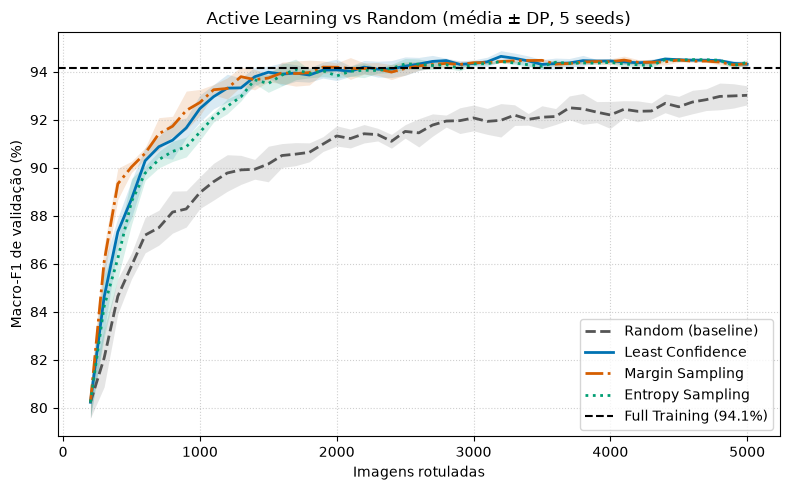

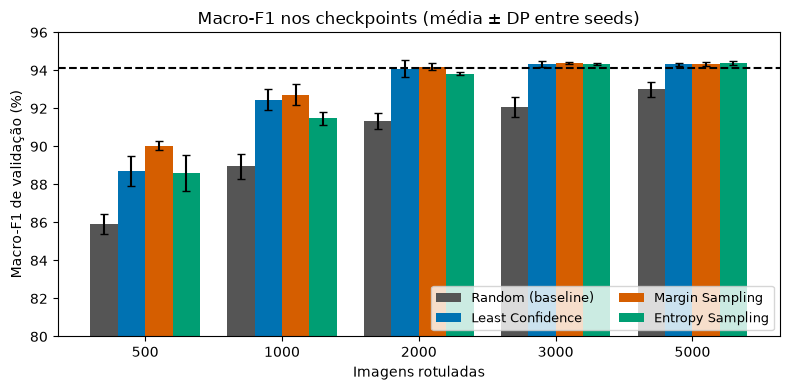

,Macro-F1 @ 1000,Macro-F1 @ 3000,Macro-F1 @ 5000,AULC (%),ΔAULC vs Random (pp),Seeds melhores que Random
Estratégia,,,,,,
Random (baseline),88.96 ± 0.66,92.07 ± 0.54,93.02 ± 0.40,90.71 ± 0.24,—,—
Least Confidence,92.46 ± 0.56,94.34 ± 0.15,94.31 ± 0.10,93.30 ± 0.12,+2.59 ± 0.14,5/5
Margin Sampling,92.72 ± 0.54,94.38 ± 0.04,94.33 ± 0.12,93.45 ± 0.12,+2.74 ± 0.17,5/5
Entropy Sampling,91.48 ± 0.35,94.32 ± 0.06,94.39 ± 0.12,93.10 ± 0.08,+2.39 ± 0.30,5/5


Valores: média ± DP entre seeds (ddof=1), Macro-F1 de validação em %; ΔAULC emparelhada por seed e descritiva.


**Macro-F1 ≥ 90% (validação)** — primeiro nº de imagens rotuladas; limiar não atingido até 5000

,seed 42,seed 123,seed 456,seed 789,seed 2026,atingiu
Random (baseline),1700,1500,1100,1200,1300,5/5
Least Confidence,700,600,700,600,700,5/5
Margin Sampling,400,600,600,500,600,5/5
Entropy Sampling,700,700,700,700,600,5/5


**Macro-F1 ≥ 92% (validação)** — primeiro nº de imagens rotuladas; limiar não atingido até 5000

,seed 42,seed 123,seed 456,seed 789,seed 2026,atingiu
Random (baseline),3600,3200,2000,3000,2700,5/5
Least Confidence,1100,900,1000,1000,1000,5/5
Margin Sampling,800,900,900,700,1000,5/5
Entropy Sampling,1000,1100,1200,1100,1100,5/5


In [73]:
if al_results_available:
    AL_LABELS = {"random": "Random (baseline)", "least_confidence": "Least Confidence",
                 "margin": "Margin Sampling", "entropy": "Entropy Sampling"}
    AL_STYLE = {"random": ("#555555", "--", "o"), "least_confidence": ("#0072B2", "-", "s"),
                "margin": ("#D55E00", "-.", "^"), "entropy": ("#009E73", ":", "D")}
    al_seeds = sorted(next(iter(al_curves.values())))
    al_grid = next(iter(al_curves["random"].values()))[0]
    al_f1 = {s: np.array([al_curves[s][seed][1] for seed in al_seeds]) * 100 for s in AL_LABELS}  # (seeds, iteracoes)

    # --- Grafico principal: media +- desvio-padrao entre seeds --------------------------------------
    fig, ax = plt.subplots(figsize=(8, 5))
    for s, label in AL_LABELS.items():
        color, ls, _ = AL_STYLE[s]
        mean, std = al_f1[s].mean(axis=0), al_f1[s].std(axis=0, ddof=1)
        ax.plot(al_grid, mean, color=color, ls=ls, lw=2, label=label)
        ax.fill_between(al_grid, mean - std, mean + std, color=color, alpha=0.15, lw=0)
    ax.axhline(full_training_macro_f1 * 100, color="black", ls="--", lw=1.5,
               label=f"Full Training ({full_training_macro_f1 * 100:.1f}%)")
    ax.set_xlabel("Imagens rotuladas")
    ax.set_ylabel("Macro-F1 de validação (%)")
    ax.set_title(f"Active Learning vs Random (média ± DP, {len(al_seeds)} seeds)")
    ax.grid(True, ls=":", alpha=0.6)
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

    # --- Grafico complementar: checkpoints ----------------------------------------------------------
    checkpoints = [500, 1000, 2000, 3000, 5000]
    cols = [int(np.flatnonzero(al_grid == b)[0]) for b in checkpoints]
    fig, ax = plt.subplots(figsize=(8, 4))
    width = 0.2
    for k, (s, label) in enumerate(AL_LABELS.items()):
        vals = al_f1[s][:, cols]
        ax.bar(np.arange(len(checkpoints)) + (k - 1.5) * width, vals.mean(axis=0), width,
               yerr=vals.std(axis=0, ddof=1), capsize=3, color=AL_STYLE[s][0], label=label)
    ax.axhline(full_training_macro_f1 * 100, color="black", ls="--", lw=1.5)
    ax.set_xticks(np.arange(len(checkpoints)), [str(b) for b in checkpoints])
    ax.set_ylim(80, 96)
    ax.set_xlabel("Imagens rotuladas")
    ax.set_ylabel("Macro-F1 de validação (%)")
    ax.set_title("Macro-F1 nos checkpoints (média ± DP entre seeds)")
    ax.legend(ncol=2, fontsize=9, loc="lower right")
    fig.tight_layout()
    plt.show()

    # --- Tabela comparativa + AULC emparelhada ------------------------------------------------------
    al_aulc = aulc_by_seed(al_curves)
    pm = lambda a: f"{np.mean(a):.2f} ± {np.std(a, ddof=1):.2f}"
    rows = []
    for s, label in AL_LABELS.items():
        d = paired_aulc_difference(al_aulc, s)
        a = np.array([al_aulc[s][seed] for seed in al_seeds]) * 100
        rows.append({"Estratégia": label,
                     **{f"Macro-F1 @ {b}": pm(al_f1[s][:, int(np.flatnonzero(al_grid == b)[0])]) for b in (1000, 3000, 5000)},
                     "AULC (%)": pm(a),
                     "ΔAULC vs Random (pp)": "—" if s == "random" else f"{d['mean'] * 100:+.2f} ± {d['std'] * 100:.2f}",
                     "Seeds melhores que Random": "—" if s == "random" else f"{d['wins']}/{d['n_seeds']}"})
    display(pd.DataFrame(rows).set_index("Estratégia"))
    print("Valores: média ± DP entre seeds (ddof=1), Macro-F1 de validação em %; ΔAULC emparelhada por seed e descritiva.")

    # --- Eficiencia de anotacao: primeiro orcamento com Macro-F1 >= limiar -------------------------------
    for threshold in (0.90, 0.92):
        table = pd.DataFrame({AL_LABELS[s]: {seed: first_budget_reaching(*al_curves[s][seed], threshold) for seed in al_seeds}
                              for s in AL_LABELS}).T
        table.columns = [f"seed {c}" for c in table.columns]
        reached = table.notna().sum(axis=1).astype(str) + f"/{len(al_seeds)}"
        table = table.apply(lambda col: col.map(lambda v: "não atingido" if pd.isna(v) else str(int(v))))
        table["atingiu"] = reached
        display(Markdown(f"**Macro-F1 ≥ {threshold * 100:.0f}% (validação)** — primeiro nº de imagens rotuladas; limiar não atingido até {al_config['max_labels']}"))
        display(table)
else:
    print("Comparação não apresentada: resultados de Active Learning em falta.")

### 10.3 Classificador baseline: treino completo avaliado no teste

Logistic Regression com todas as imagens de treino (manifesto `train`), avaliada no teste independente.

In [74]:
# Baseline: treino completo (manifesto train) avaliado no teste independente (manifesto test)

archive = load_feature_archive(FEATURES_FILE)  # falha se as exclusoes mudaram
X_features, y_labels = archive['X'], archive['y']
class_names = list(archive['class_names'])
partitions = read_partitions()
train_rows = feature_rows(archive['filenames'], partitions['train'])
test_rows = feature_rows(archive['filenames'], partitions['test'])
X_train, y_train = X_features[train_rows], y_labels[train_rows]
X_test, y_test = X_features[test_rows], y_labels[test_rows]

classifier = LogisticRegression(max_iter=1000, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)
baseline_macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print(f"Macro-F1 da Classificação Base (PyTorch + Logistic Regression): {baseline_macro_f1 * 100:.2f}%")

Macro-F1 da Classificação Base (PyTorch + Logistic Regression): 94.13%


### 10.4 Matriz de confusão e relatório de classificação


--- Classification Report ---
              precision    recall  f1-score   support

     battery       0.97      0.98      0.98       189
  biological       0.98      0.99      0.99       198
 brown-glass       0.98      0.97      0.97       122
   cardboard       0.97      0.95      0.96       178
     clothes       0.99      0.98      0.99      1064
 green-glass       0.93      0.96      0.95       126
       metal       0.92      0.88      0.90       154
       paper       0.92      0.95      0.93       210
     plastic       0.84      0.90      0.87       174
       shoes       0.96      0.97      0.96       396
       trash       0.95      0.92      0.93       138
 white-glass       0.90      0.84      0.87       155

    accuracy                           0.96      3104
   macro avg       0.94      0.94      0.94      3104
weighted avg       0.96      0.96      0.96      3104



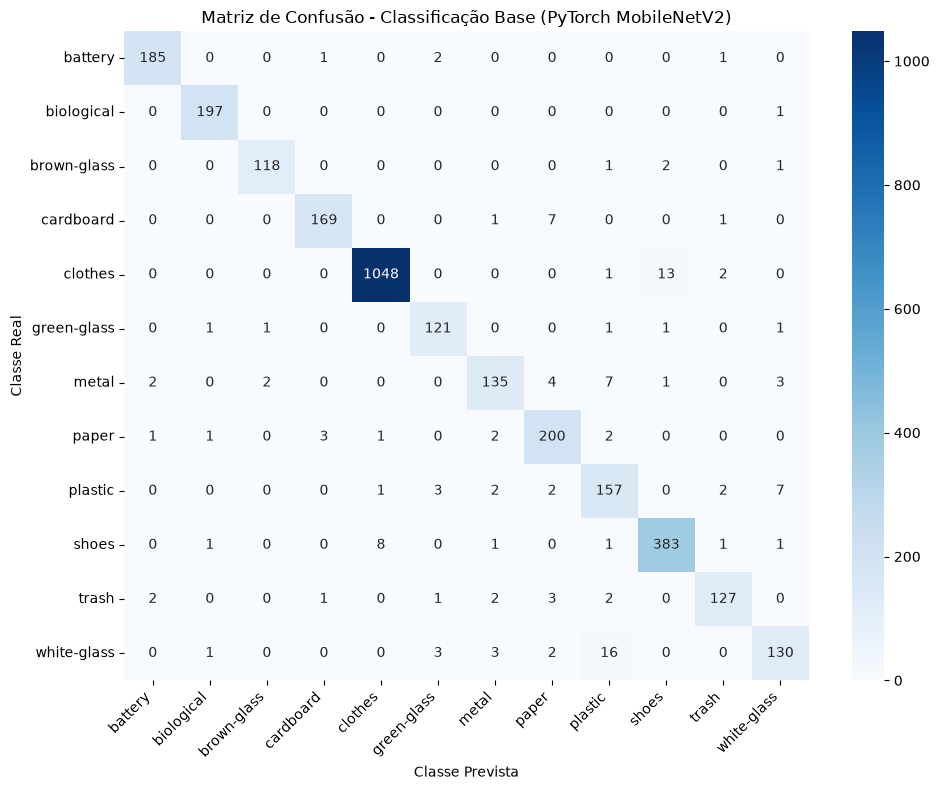

In [75]:
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusão - Classificação Base (PyTorch MobileNetV2)')
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 11. Conclusions

- **Dataset:** Kaggle v1 com 15 515 imagens; após revisão visual humana de três duplicados exatos com rótulos
  contraditórios, o dataset efetivo tem 15 512 (os rótulos Kaggle nunca são alterados).
- **Protocolo comum:** treino 10 856, validação 1 552, teste 3 104; pool inicial 200 e não rotulado 10 656,
  exclusivamente do treino; grupos de duplicados nunca atravessam splits.
- **Active Learning:** protocolo implementado (4 estratégias × 5 seeds, 200 → 5 000 rótulos, Macro-F1 de validação,
  AULC, Full Training Baseline); as conclusões dependem dos resultados apresentados na secção 10.
- **Pendentes:** política de consultas por imagem ou grupo para duplicados quase exatos e critério prévio de desempate Macro-F1/AULC. O teste só é consultado com o protocolo congelado.